# GPAC Amharic N-gram Project

Run the shared setup cell below first; every part after it uses the same Drive mount, imports and `CORPUS_PATH`.

1. Part 1 — unigram/bigram counts (SQLite)
2. Part 2 — trigram/four-gram models & sentence generation
3. Part 3 — stopword removal & word clouds
4. Part 4 — probability, train/test split & model evaluation

In [ ]:
from google.colab import drive
drive.mount('/content/gdrive')

import os, re, time, pickle, csv, math, random, sys, zlib, gc, shutil, sqlite3, codecs, glob, subprocess
from pathlib import Path
from collections import Counter, defaultdict
from array import array
import numpy as np
import pandas as pd

DRIVE = Path("/content/gdrive/MyDrive")

CORPUS_PATH = DRIVE / "GPAC.txt"
if not CORPUS_PATH.is_file() and (DRIVE / "Corpus" / "GPAC.txt").is_file():
    CORPUS_PATH = DRIVE / "Corpus" / "GPAC.txt"
print("Corpus found:", CORPUS_PATH.is_file(), "->", CORPUS_PATH)

PROJECT_DIR = DRIVE / "GPAC_member1_results"
PROJECT_DIR.mkdir(parents=True, exist_ok=True)
DB_PATH = Path("/content/ngram_counts_local.sqlite")
DB_BACKUP = PROJECT_DIR / "ngram_counts_local_backup.sqlite"
if not DB_PATH.exists() and DB_BACKUP.exists():
    shutil.copy(DB_BACKUP, DB_PATH)
    print("Restored database from Drive backup -> skip the database-build cell in Part 1.")


This is the shared environment/setup cell.

Member 1: Corpus setup, unigram/bigram counts & SQLite store

 The SQLite database is kept on Colab's local disk and backed up to Drive. Streams the full GPAC corpus into a SQLite database of unigram/bigram counts, computes probabilities and exports results.


In [ ]:
for item in PROJECT_DIR.iterdir():
    if item.is_file():
        size_mb = item.stat().st_size / (1024**2)
        print(f"FILE   {item.name} — {size_mb:.1f} MB")
    else:
        print(f"FOLDER {item.name}")

FOLDER .ipynb_checkpoints
FILE   GPAC.txt — 1013.8 MB
FILE   Untitled.ipynb — 0.0 MB


This inventory reports the files available in the project directory and their sizes.

In [ ]:
print("Corpus exists:", CORPUS_PATH.is_file())

if CORPUS_PATH.is_file():
    print(f"Corpus size: {CORPUS_PATH.stat().st_size / (1024**3):.3f} GiB")

Corpus exists: True
Corpus size: 0.990 GiB


This checks whether the corpus file exists and reports its size. A positive existence check and a plausible file size are prerequisites for corpus-processing steps.

In [ ]:
SENTENCE_END_RE = re.compile(r"፡፡|።|፧|\?|!+")
PUNCTUATION_RE = re.compile(
    r"""[፡።፣፤፥፦፧፨?!,.;:()\[\]{}<>"'/%—–-]+"""
)

SAMPLE_SIZE = 5_000_000

start = time.perf_counter()

with CORPUS_PATH.open("r", encoding="utf-8") as f:
    sample = f.read(SAMPLE_SIZE)

# Count only complete sentences, avoiding a partial final sentence.
matches = list(SENTENCE_END_RE.finditer(sample))
if not matches:
    raise ValueError("No sentence-ending punctuation found in sample.")

sample = sample[:matches[-1].end()]
raw_sentences = SENTENCE_END_RE.split(sample)

unigrams = Counter()
bigrams = Counter()
sentence_count = 0
token_count = 0

for sentence in raw_sentences:
    cleaned = PUNCTUATION_RE.sub(" ", sentence)
    tokens = cleaned.split()

    if not tokens:
        continue

    sentence_count += 1
    token_count += len(tokens)
    unigrams.update(tokens)
    bigrams.update(zip(tokens, tokens[1:]))

elapsed = time.perf_counter() - start

print(f"Characters read: {len(sample):,}")
print(f"Sentences counted: {sentence_count:,}")
print(f"Tokens counted: {token_count:,}")
print(f"Unique unigrams: {len(unigrams):,}")
print(f"Unique bigrams: {len(bigrams):,}")
print(f"Elapsed time: {elapsed:.2f} seconds")
print(f"Estimated full-file time at this rate: "
      f"{elapsed * CORPUS_PATH.stat().st_size / len(sample) / 3600:.2f} hours")

print("\nTop 10 unigrams:")
for word, count in unigrams.most_common(10):
    print(repr(word), count)

print("\nTop 10 bigrams:")
for pair, count in bigrams.most_common(10):
    print(" ".join(pair), count)


Characters read: 4,999,970
Sentences counted: 75,784
Tokens counted: 945,371
Unique unigrams: 166,363
Unique bigrams: 668,745
Elapsed time: 3.11 seconds
Estimated full-file time at this rate: 0.18 hours

Top 10 unigrams:
'ነው' 17420
'ላይ' 8180
'ግን' 4708
'ወደ' 4522
'ነበር' 4327
'ውስጥ' 4133
'እና' 3891
'ጋር' 3586
'ነገር' 3379
'አንድ' 3147

Top 10 bigrams:
ዓ ም 1031
ነገር ግን 668
ማለት ነው 564
ብቻ ሳይሆን 489
ብቻ ነው 469
ዶ ር 350
አዲስ አበባ 331
ሚሊዮን ዶላር 309
ምን ያህል 278
ወ ሮ 214


This defines the project's sentence-boundary and punctuation rules. These rules affect every token and n-gram count, we will keep them consistent across team members; punctuation that is treated differently can change counts.

In [ ]:
disk = shutil.disk_usage(DB_PATH.parent)

print(f"Free space on Colab disk {disk.free / (1024**3):.2f} GiB")
print(f"Corpus size: {CORPUS_PATH.stat().st_size / (1024**3):.3f} GiB")
print(f"New database path: {DB_PATH}")
print(f"Database already exists: {DB_PATH.exists()}")

print("\nExisting database-related files:")
for p in list(DB_PATH.parent.glob("ngram_counts*.sqlite*")) + list(PROJECT_DIR.glob("*.sqlite*")):
    print(f"{p.name} — {p.stat().st_size / (1024**3):.3f} GiB")

Free space on D: 164.86 GiB
Corpus size: 0.990 GiB
New database path: D:\GPAC\ngram_counts_local.sqlite
Database already exists: False

Existing database-related files:


This reports available disk space. Large corpus and intermediate files can require substantial storage, so we will check the free-space value before creating additional copies or exports.

In [ ]:
# --------------------------------------------------
# 1. Paths and settings
# --------------------------------------------------

CHUNK_BYTES = 1_000_000
COMMIT_EVERY_CHUNKS = 5
PROGRESS_EVERY_BATCHES = 10

SENTENCE_END_RE = re.compile(r"፡፡|።|፧|\?|!+")
PUNCTUATION_RE = re.compile(
    r"""[፡።፣፤፥፦፧፨?!,.;:()\[\]{}<>"'/%—–-]+"""
)

# --------------------------------------------------
# 2. Validate paths
# --------------------------------------------------
if not CORPUS_PATH.is_file():
    raise FileNotFoundError(f"Corpus not found: {CORPUS_PATH}")

if DB_PATH.exists():
    raise FileExistsError(
        f"Database already exists: {DB_PATH}\n"
        "This script will not overwrite it. Inspect or resume it instead."
    )

PROJECT_DIR.mkdir(parents=True, exist_ok=True)
corpus_size = CORPUS_PATH.stat().st_size

# --------------------------------------------------
# 3. Create database and checkpoint
# --------------------------------------------------
conn = sqlite3.connect(DB_PATH, timeout=60)

conn.execute("PRAGMA journal_mode=WAL")
conn.execute("PRAGMA synchronous=NORMAL")
conn.execute("PRAGMA cache_size=-64000")

conn.executescript("""
CREATE TABLE unigrams (
    token TEXT PRIMARY KEY,
    count INTEGER NOT NULL
);

CREATE TABLE bigrams (
    w1 TEXT NOT NULL,
    w2 TEXT NOT NULL,
    count INTEGER NOT NULL,
    PRIMARY KEY (w1, w2)
);

CREATE TABLE run_state (
    id INTEGER PRIMARY KEY CHECK (id = 1),
    corpus_path TEXT NOT NULL,
    corpus_size INTEGER NOT NULL,
    byte_offset INTEGER NOT NULL,
    carry TEXT NOT NULL,
    sentences INTEGER NOT NULL,
    tokens INTEGER NOT NULL,
    complete INTEGER NOT NULL
);
""")

conn.execute("""
INSERT INTO run_state
VALUES (1, ?, ?, 0, '', 0, 0, 0)
""", (str(CORPUS_PATH.resolve()), corpus_size))
conn.commit()

# --------------------------------------------------
# 4. Counting helpers
# --------------------------------------------------
batch_unigrams = Counter()
batch_bigrams = Counter()
batch_sentences = 0
batch_tokens = 0

def count_sentence(sentence):
    global batch_sentences, batch_tokens

    cleaned = PUNCTUATION_RE.sub(" ", sentence)
    tokens = cleaned.split()

    if not tokens:
        return

    batch_unigrams.update(tokens)
    batch_bigrams.update(zip(tokens, tokens[1:]))

    batch_sentences += 1
    batch_tokens += len(tokens)


def commit_batch(offset, carry, total_sentences,
                 total_tokens, complete=False):
    """Save counts and their matching checkpoint atomically."""
    global batch_sentences, batch_tokens

    with conn:
        conn.executemany("""
            INSERT INTO unigrams(token, count)
            VALUES (?, ?)
            ON CONFLICT(token) DO UPDATE SET
                count = count + excluded.count
        """, batch_unigrams.items())

        conn.executemany("""
            INSERT INTO bigrams(w1, w2, count)
            VALUES (?, ?, ?)
            ON CONFLICT(w1, w2) DO UPDATE SET
                count = count + excluded.count
        """, [
            (w1, w2, count)
            for (w1, w2), count in batch_bigrams.items()
        ])

        conn.execute("""
            UPDATE run_state
            SET byte_offset = ?,
                carry = ?,
                sentences = ?,
                tokens = ?,
                complete = ?
            WHERE id = 1
        """, (
            offset, carry,
            total_sentences + batch_sentences,
            total_tokens + batch_tokens,
            int(complete)
        ))

    total_sentences += batch_sentences
    total_tokens += batch_tokens

    batch_unigrams.clear()
    batch_bigrams.clear()
    batch_sentences = 0
    batch_tokens = 0

    return total_sentences, total_tokens


# --------------------------------------------------
# 5. Stream through the corpus
# --------------------------------------------------
start_time = time.perf_counter()
total_sentences = 0
total_tokens = 0
batches = 0
chunks_since_commit = 0

carry = ""
decoder = codecs.getincrementaldecoder("utf-8")()

try:
    with CORPUS_PATH.open("rb") as f:
        while True:
            raw = f.read(CHUNK_BYTES)

            if not raw:
                # Flush the UTF-8 decoder at EOF.
                carry += decoder.decode(b"", final=True)

                # Process all complete sentences remaining.
                last_end = 0
                for match in SENTENCE_END_RE.finditer(carry):
                    count_sentence(carry[last_end:match.end()])
                    last_end = match.end()

                # Count a final sentence even without ending punctuation.
                count_sentence(carry[last_end:])

                total_sentences, total_tokens = commit_batch(
                    f.tell(), "", total_sentences,
                    total_tokens, complete=True
                )
                break

            carry += decoder.decode(raw, final=False)

            # Only count complete sentences. Keep the unfinished
            # sentence in carry for the next chunk.
            last_end = 0
            for match in SENTENCE_END_RE.finditer(carry):
                count_sentence(carry[last_end:match.end()])
                last_end = match.end()

            carry = carry[last_end:]

            # Rewind the checkpoint over any incomplete UTF-8 bytes.
            pending_bytes = decoder.getstate()[0]
            safe_offset = f.tell() - len(pending_bytes)

            chunks_since_commit += 1

            if chunks_since_commit >= COMMIT_EVERY_CHUNKS:
                total_sentences, total_tokens = commit_batch(
                    safe_offset, carry, total_sentences,
                    total_tokens
                )

                chunks_since_commit = 0
                batches += 1

                if batches % PROGRESS_EVERY_BATCHES == 0:
                    elapsed = time.perf_counter() - start_time
                    percent = 100 * safe_offset / corpus_size

                    print(
                        f"{percent:.1f}% | "
                        f"{safe_offset:,}/{corpus_size:,} bytes | "
                        f"Sentences: {total_sentences:,} | "
                        f"Tokens: {total_tokens:,} | "
                        f"Elapsed: {elapsed / 60:.1f} min",
                        flush=True
                    )

    elapsed = time.perf_counter() - start_time
    print("\nCounting finished.")
    print(f"Sentences: {total_sentences:,}")
    print(f"Tokens: {total_tokens:,}")
    print(f"Elapsed: {elapsed / 60:.2f} minutes")
    print(f"Database: {DB_PATH}")

except Exception:
    print(
        "\nThe run stopped. Previously committed batches and their "
        "checkpoint remain in the database. Do not delete the database."
    )
    raise

finally:
    conn.close()



4.7% | 50,000,000/1,063,098,071 bytes | Sentences: 291,831 | Tokens: 3,697,055 | Elapsed: 4.0 min
9.4% | 99,999,998/1,063,098,071 bytes | Sentences: 588,703 | Tokens: 7,374,387 | Elapsed: 8.9 min
14.1% | 149,999,998/1,063,098,071 bytes | Sentences: 844,512 | Tokens: 11,013,483 | Elapsed: 16.8 min
18.8% | 200,000,000/1,063,098,071 bytes | Sentences: 1,086,307 | Tokens: 14,643,444 | Elapsed: 28.5 min
23.5% | 249,999,998/1,063,098,071 bytes | Sentences: 1,310,323 | Tokens: 18,280,570 | Elapsed: 42.5 min
28.2% | 300,000,000/1,063,098,071 bytes | Sentences: 1,532,583 | Tokens: 21,964,878 | Elapsed: 54.8 min
32.9% | 349,999,998/1,063,098,071 bytes | Sentences: 1,728,747 | Tokens: 25,611,459 | Elapsed: 92.0 min
37.6% | 399,999,998/1,063,098,071 bytes | Sentences: 1,971,642 | Tokens: 29,311,280 | Elapsed: 105.6 min
42.3% | 450,000,000/1,063,098,071 bytes | Sentences: 2,185,268 | Tokens: 32,965,589 | Elapsed: 117.4 min
47.0% | 499,999,998/1,063,098,071 bytes | Sentences: 2,411,058 | Tokens: 36,

This establishes project paths and settings. we verify that the corpus, database, backup, and results paths match the mounted Drive layout before continuing.

In [ ]:
db_path = DB_PATH

print("Database exists:", db_path.exists())
print("Database size (MB):", round(db_path.stat().st_size / (1024**2), 2))

for suffix in ("-wal", "-shm"):
    p = Path(str(db_path) + suffix)
    print(f"{suffix} exists:", p.exists(),
          f"| size (MB): {round(p.stat().st_size / (1024**2), 2) if p.exists() else 0}")

con = sqlite3.connect(f"file:{db_path.as_posix()}?mode=ro", uri=True)

print("\nTable counts:")
for table in ("unigrams", "bigrams", "run_state"):
    try:
        print(table, con.execute(
            f"SELECT COUNT(*) FROM {table}"
        ).fetchone()[0])
    except sqlite3.Error as e:
        print(table, "ERROR:", e)

print("\nRun status:")
try:
    print(con.execute("""
        SELECT corpus_path, corpus_size, byte_offset,
               sentences, tokens, complete
        FROM run_state
    """).fetchall())
except sqlite3.Error as e:
    print("ERROR:", e)

con.close()


Database exists: True
Database size (MB): 2140.34
-wal exists: False | size (MB): 0
-shm exists: False | size (MB): 0

Table counts:
unigrams 1936354
bigrams 24501063
run_state 1

Run status:
[('D:\\GPAC\\GPAC.txt', 1063098071, 1063098071, 5057775, 77760019, 1)]


This checks database presence and size. The database should exist and have a non-zero size before read-only queries or backup checks are attempted.

In [ ]:
db_path = DB_PATH
con = sqlite3.connect(f"file:{db_path.as_posix()}?mode=ro", uri=True)

# Total token count from the verified processing run
total_tokens = con.execute(
    "SELECT tokens FROM run_state"
).fetchone()[0]

# Unigram counts and maximum-likelihood probabilities
unigrams = pd.read_sql_query("""
    SELECT token, count
    FROM unigrams
    ORDER BY count DESC
    LIMIT 10
""", con)

unigrams["probability"] = unigrams["count"] / total_tokens

# Bigram counts and conditional probabilities P(second word | first word)
bigrams = pd.read_sql_query("""
    SELECT w1, w2, count
    FROM bigrams
    ORDER BY count DESC
    LIMIT 10
""", con)

# Fetch each first word's total unigram count
first_words = tuple(bigrams["w1"].unique())
placeholders = ",".join("?" for _ in first_words)

word_counts = pd.read_sql_query(
    f"SELECT token, count FROM unigrams WHERE token IN ({placeholders})",
    con,
    params=first_words
)

count_lookup = dict(zip(word_counts["token"], word_counts["count"]))

bigrams["probability"] = bigrams.apply(
    lambda row: row["count"] / count_lookup[row["w1"]],
    axis=1
)

print("Total tokens:", f"{total_tokens:,}")

print("\nTop 10 unigrams:")
display(unigrams)

print("\nTop 10 bigrams:")
display(bigrams)

con.close()


Total tokens: 77,760,019

Top 10 unigrams:


,token,count,probability
0,ነው,1166197,0.014997
1,ላይ,754597,0.009704
2,ውስጥ,346289,0.004453
3,ወደ,330973,0.004256
4,እና,318783,0.004100
5,ጋር,291521,0.003749
6,ነበር,275023,0.003537
7,ግን,271505,0.003492
8,ጊዜ,244085,0.003139
9,ነገር,217662,0.002799



Top 10 bigrams:


,w1,w2,count,probability
0,ዓ,ም,104251,0.970300
1,ነገር,ግን,44743,0.205562
2,ዶ,ር,35618,0.984929
3,ማለት,ነው,32380,0.339823
4,ብቻ,ሳይሆን,32261,0.189372
5,አዲስ,አበባ,31355,0.352922
6,1,1,28958,0.296270
7,ብቻ,ነው,24681,0.144877
8,በአዲስ,አበባ,24036,0.726624
9,ምክር,ቤት,23902,0.558641


This opens the database in read-only mode and summarizes its token data. So we treat these counts as a consistency check against the corpus-processing results; differences may indicate preprocessing or database-version mismatches.

In [ ]:
# Project paths
PROJECT = PROJECT_DIR
RESULTS = PROJECT / "results"
RESULTS.mkdir(parents=True, exist_ok=True)

DB = DB_PATH

# Read-only connection: this code will not modify the database
con = sqlite3.connect(f"file:{DB.as_posix()}?mode=ro", uri=True)

# Corpus summary
summary = pd.read_sql_query("""
    SELECT corpus_path, corpus_size, sentences, tokens, complete
    FROM run_state
""", con)

summary.to_csv(
    RESULTS / "corpus_summary.csv",
    index=False,
    encoding="utf-8-sig"
)

# Top 10 unigrams and their probabilities
top_unigrams = pd.read_sql_query("""
    SELECT token, count,
           CAST(count AS REAL) / (
               SELECT tokens FROM run_state
           ) AS probability
    FROM unigrams
    ORDER BY count DESC
    LIMIT 10
""", con)

top_unigrams.to_csv(
    RESULTS / "top10_unigrams.csv",
    index=False,
    encoding="utf-8-sig"
)

# Top 10 bigrams and conditional probabilities P(w2 | w1)
top_bigrams = pd.read_sql_query("""
    SELECT b.w1, b.w2, b.count,
           CAST(b.count AS REAL) / u.count AS probability
    FROM bigrams AS b
    JOIN unigrams AS u ON u.token = b.w1
    ORDER BY b.count DESC
    LIMIT 10
""", con)

top_bigrams.to_csv(
    RESULTS / "top10_bigrams.csv",
    index=False,
    encoding="utf-8-sig"
)

con.close()

print("Saved files:")
for path in sorted(RESULTS.glob("*.csv")):
    print(path.name, "|", path.stat().st_size, "bytes")

print("\nTop unigrams:")
display(top_unigrams)

print("\nTop bigrams:")
display(top_bigrams)


Saved files:
corpus_summary.csv | 102 bytes
top10_bigrams.csv | 441 bytes
top10_unigrams.csv | 401 bytes

Top unigrams:


,token,count,probability
0,ነው,1166197,0.014997
1,ላይ,754597,0.009704
2,ውስጥ,346289,0.004453
3,ወደ,330973,0.004256
4,እና,318783,0.004100
5,ጋር,291521,0.003749
6,ነበር,275023,0.003537
7,ግን,271505,0.003492
8,ጊዜ,244085,0.003139
9,ነገር,217662,0.002799



Top bigrams:


,w1,w2,count,probability
0,ዓ,ም,104251,0.970300
1,ነገር,ግን,44743,0.205562
2,ዶ,ር,35618,0.984929
3,ማለት,ነው,32380,0.339823
4,ብቻ,ሳይሆን,32261,0.189372
5,አዲስ,አበባ,31355,0.352922
6,1,1,28958,0.296270
7,ብቻ,ነው,24681,0.144877
8,በአዲስ,አበባ,24036,0.726624
9,ምክር,ቤት,23902,0.558641


This prepares the results directory and output locations. Keeping generated files in a dedicated folder makes the analysis reproducible and easier to audit.

In [ ]:
db_path = DB_PATH
con = sqlite3.connect(f"file:{db_path.as_posix()}?mode=ro", uri=True)

# Inspect the available tables
tables = pd.read_sql_query("""
    SELECT name
    FROM sqlite_master
    WHERE type = 'table'
    ORDER BY name
""", con)

print("Tables in database:")
display(tables)

# Correct conditional probability:
# P(w2 | w1) = count(w1, w2) / total counts of all bigrams starting with w1
top_bigrams_corrected = pd.read_sql_query("""
    WITH outgoing AS (
        SELECT w1, SUM(count) AS outgoing_count
        FROM bigrams
        GROUP BY w1
    )
    SELECT b.w1, b.w2, b.count,
           o.outgoing_count,
           CAST(b.count AS REAL) / o.outgoing_count AS probability
    FROM bigrams AS b
    JOIN outgoing AS o ON b.w1 = o.w1
    ORDER BY b.count DESC
    LIMIT 10
""", con)

print("Top 10 bigrams with corrected conditional probabilities:")
display(top_bigrams_corrected)

con.close()


Tables in database:


,name
0,bigrams
1,run_state
2,unigrams


Top 10 bigrams with corrected conditional probabilities:


,w1,w2,count,outgoing_count,probability
0,ዓ,ም,104251,107410,0.970589
1,ነገር,ግን,44743,216514,0.206652
2,ዶ,ር,35618,36155,0.985147
3,ማለት,ነው,32380,94568,0.342399
4,ብቻ,ሳይሆን,32261,169139,0.190737
5,አዲስ,አበባ,31355,88829,0.352982
6,1,1,28958,97378,0.297377
7,ብቻ,ነው,24681,169139,0.145921
8,በአዲስ,አበባ,24036,33079,0.726624
9,ምክር,ቤት,23902,42750,0.559111


This inspects the database schema/tables. We will use the reported table and column names to verify that later SQL queries target the expected structures.

In [ ]:
# File locations
db_path = DB_PATH
results_dir = PROJECT_DIR / "results"
output_path = results_dir / "top10_bigrams.csv"

results_dir.mkdir(parents=True, exist_ok=True)

# Calculate and export the corrected top 10 bigrams
query = """
WITH top_bigrams AS (
    SELECT w1, w2, count
    FROM bigrams
    ORDER BY count DESC
    LIMIT 10
),
outgoing AS (
    SELECT b.w1, SUM(b.count) AS outgoing_count
    FROM bigrams AS b
    JOIN (
        SELECT DISTINCT w1
        FROM top_bigrams
    ) AS t ON b.w1 = t.w1
    GROUP BY b.w1
)
SELECT
    t.w1,
    t.w2,
    t.count,
    o.outgoing_count,
    ROUND(
        CAST(t.count AS REAL) / o.outgoing_count,
        6
    ) AS probability
FROM top_bigrams AS t
JOIN outgoing AS o ON t.w1 = o.w1
ORDER BY t.count DESC;
"""

with sqlite3.connect(f"file:{db_path.as_posix()}?mode=ro", uri=True) as conn:
    df = pd.read_sql_query(query, conn)

df.to_csv(output_path, index=False, encoding="utf-8-sig")

print("Export complete!")
print(f"Saved to: {output_path}")
print(f"Rows exported: {len(df)}")
display(df)


Export complete!
Saved to: D:\GPAC\results\top10_bigrams.csv
Rows exported: 10


,w1,w2,count,outgoing_count,probability
0,ዓ,ም,104251,107410,0.970589
1,ነገር,ግን,44743,216514,0.206652
2,ዶ,ር,35618,36155,0.985147
3,ማለት,ነው,32380,94568,0.342399
4,ብቻ,ሳይሆን,32261,169139,0.190737
5,አዲስ,አበባ,31355,88829,0.352982
6,1,1,28958,97378,0.297377
7,ብቻ,ነው,24681,169139,0.145921
8,በአዲስ,አበባ,24036,33079,0.726624
9,ምክር,ቤት,23902,42750,0.559111


This configures an output path for a database/query result and confirm the destination is correct before relying on the exported file in later analysis.

In [ ]:
%pip install streamlit

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.1.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


This installs Streamlit in the current notebook environment. The installation output confirms whether the dependency is available; installation may need to be repeated in a fresh Colab runtime.

In [ ]:
import streamlit as st
print("Streamlit version:", st.__version__)

Streamlit version: 1.66.1


This verifies the installed Streamlit version. A successful version print confirms that the import works in the current runtime.

In [ ]:
source = DB_PATH
backup = DB_BACKUP

with sqlite3.connect(source) as src:
    print("WAL checkpoint:", src.execute(
        "PRAGMA wal_checkpoint(TRUNCATE)"
    ).fetchone())

    with sqlite3.connect(backup) as dst:
        src.backup(dst)

print("Backup created:", backup)
print("Backup size:", round(backup.stat().st_size / (1024**3), 2), "GB")

WAL checkpoint: (0, 0, 0)
Backup created: D:\GPAC\ngram_counts_local_backup.sqlite
Backup size: 2.09 GB


This checks/checkpoints SQLite write-ahead-log state and creates or verifies a database backup. Use the status output to confirm the database is in a consistent state before sharing or moving it.

# Part 2 - Trigram / four-gram models & sentence generation

(Drive already mounted by the shared setup cell). Top-10 trigrams/four-grams, sentence probability and random sentence generation.


# Member 2: Trigram/Four-gram Models and Sentence Generation

**Assignment tasks covered:** 1.3 (top 10 n-grams for n = 3, 4), 1.7 (sentence probability), 1.8 (random sentence generation).

**Preprocessing:** identical to Member 1 (same sentence-ending markers and punctuation regex). Verified: both give 5,057,775 sentences and 77,760,019 tokens on the full corpus.

**Probability method:** maximum likelihood, same as Member 1's bigram table:
P(w_n | context) = count(context w_n) / outgoing_count(context), where outgoing_count = how often the context is followed by any word.

**Memory approach:** the full corpus has ~42M unique trigrams and ~45M unique four-grams, too many for Colab RAM. Words are split into 8 fixed groups (CRC32 hash); each pass counts only n-grams whose first word is in one group. N-grams with the same context always land in the same group, so counts and probabilities are exact.

Run the cells in order in Google Colab. The corpus must be in My Drive as `GPAC.txt`.

## 1. Setup: paths, preprocessing rules, streaming reader

In [ ]:
OUT = Path("/content/gdrive/MyDrive/GPAC_member2_results")
OUT.mkdir(parents=True, exist_ok=True)

# Copied exactly from Member 1's preprocessing
SENT_END = re.compile(r"፡፡|።|፧|\?|!+")
PUNCT_RE = re.compile(r"""[፡።፣፤፥፦፧፨?!,.;:()\[\]{}<>"'/%—–-]+""")

def stream_sentences(path, chunk_chars=1_000_000):
    """Read the file in chunks and yield one sentence (list of tokens) at a time."""
    buffer = ""
    with open(path, encoding="utf-8") as f:
        while True:
            chunk = f.read(chunk_chars)
            if not chunk:
                break
            buffer += chunk
            last_end = 0
            for m in SENT_END.finditer(buffer):
                tokens = PUNCT_RE.sub(" ", buffer[last_end:m.end()]).split()
                if tokens:
                    yield tokens
                last_end = m.end()
            buffer = buffer[last_end:]      # keep the unfinished sentence for the next chunk
    tokens = PUNCT_RE.sub(" ", buffer).split()
    if tokens:
        yield tokens

This initializes the output folder and streaming/preprocessing configuration for the n-gram analysis. Keeping these paths and preprocessing rules stable is important for reproducible counts.

## 2. Full-corpus check and unigram counts (must match Member 1)

In [ ]:
start = time.time()
unigrams = Counter()
n_sentences = 0
for tokens in stream_sentences(CORPUS_PATH):
    n_sentences += 1
    unigrams.update(tokens)

n_tokens = sum(unigrams.values())
print(f"Sentences      : {n_sentences:,}   (Member 1: 5,057,775)")
print(f"Tokens         : {n_tokens:,}   (Member 1: 77,760,019)")
print(f"Unique unigrams: {len(unigrams):,}")
with open(OUT / "full_unigrams.pkl", "wb") as f:
    pickle.dump({"unigrams": unigrams, "sentences": n_sentences}, f)
print(f"Time: {(time.time()-start)/60:.1f} min")

This counts unigrams and sentences over the corpus stream. The sentence and token totals provide a baseline for comparison with the other project sections; investigate any discrepancy before interpreting model results.

## 3. Sample n-grams (n = 1 to 4) from one sentence

In [ ]:
example = PUNCT_RE.sub(" ", "ኢትዮጵያ በአፍሪካ ቀንድ ትገኛለች።").split()
for n in range(1, 5):
    grams = [" ".join(example[i:i+n]) for i in range(len(example) - n + 1)]
    print(f"{n}-grams: {grams}")

This demonstrates how the same example sentence is represented as 1- through 4-grams. It is a small sanity check that the token order and n-gram window sizes behave as expected.

## 4. Count trigrams and four-grams on the full corpus (8 groups)
Resumable: finished groups are saved to Drive and skipped on re-run.

In [ ]:
N_PARTS = 8
PART_DIR = OUT / "parts"
PART_DIR.mkdir(exist_ok=True)

# Fixed group number 0-7 for every word (stable across restarts)
group = {w: zlib.crc32(w.encode("utf-8")) % N_PARTS for w in unigrams}

def top_with_prob(counter, k=50):
    """Top k n-grams plus how often their context is followed by any word."""
    top = counter.most_common(k)
    needed = {g.rsplit(" ", 1)[0] for g, _ in top}
    outgoing = Counter()
    for g, c in counter.items():
        ctx = g.rsplit(" ", 1)[0]
        if ctx in needed:
            outgoing[ctx] += c
    return [(g, c, outgoing[g.rsplit(" ", 1)[0]]) for g, c in top]

start = time.time()
for part in range(N_PARTS):
    part_file = PART_DIR / f"part_{part}.pkl"
    if part_file.exists():
        print(f"Group {part}: already done, skipping")
        continue
    tri, four = Counter(), Counter()
    for tokens in stream_sentences(CORPUS_PATH):
        g = [group[t] for t in tokens]
        L = len(tokens)
        for i in range(L - 2):
            if g[i] == part:
                tri[" ".join(tokens[i:i+3])] += 1
                if i + 3 < L:
                    four[" ".join(tokens[i:i+4])] += 1
    result = {"tri_unique": len(tri), "tri_total": sum(tri.values()),
              "four_unique": len(four), "four_total": sum(four.values()),
              "tri_top": top_with_prob(tri), "four_top": top_with_prob(four)}
    with open(part_file, "wb") as f:
        pickle.dump(result, f)
    print(f"Group {part}: {result['tri_unique']:,} trigrams, {result['four_unique']:,} four-grams | "
          f"{(time.time()-start)/60:.1f} min")
    del tri, four
    gc.collect()
print("All groups done.")

This splits the corpus work into fixed groups and saves progress so long-running counting can resume.

## 5. Top 10 trigrams and four-grams (task 1.3)

In [ ]:
parts = [pickle.load(open(PART_DIR / f"part_{p}.pkl", "rb")) for p in range(N_PARTS)]

for order, name, n in [("tri", "trigrams", 3), ("four", "fourgrams", 4)]:
    unique = sum(p[order + "_unique"] for p in parts)
    total = sum(p[order + "_total"] for p in parts)
    top10 = sorted((x for p in parts for x in p[order + "_top"]), key=lambda x: -x[1])[:10]

    print(f"\nTop 10 {name}  (unique: {unique:,}, total: {total:,})")
    for g, c, out in top10:
        print(f"  {c:>8,}  {g}   P = {c:,} / {out:,} = {c/out:.4f}")

    with open(OUT / f"top10_{name}_full.csv", "w", newline="", encoding="utf-8-sig") as f:
        w = csv.writer(f)
        w.writerow([f"w{i}" for i in range(1, n + 1)] + ["count", "outgoing_count", "probability"])
        for g, c, out in top10:
            w.writerow(g.split(" ") + [c, out, round(c / out, 6)])

This merges the saved partial counts and displays the most frequent trigrams and four-grams. Frequent sequences reveal recurring local word patterns, but frequency alone does not establish grammatical correctness or semantic importance.

## 6. Sentence probability (task 1.7)
Models: MLE bigram/trigram/four-gram, Laplace four-gram, and linear interpolation (weights 0.4/0.3/0.2/0.1, re-normalised over the orders available at each position).

In [ ]:
test_sentences = [
    "ኢትዮጵያ በአፍሪካ ቀንድ ትገኛለች።",      # the given sentence
    "ትገኛለች ቀንድ በአፍሪካ ኢትዮጵያ።",      # same words, scrambled order
    "አዲስ አበባ የኢትዮጵያ ዋና ከተማ ናት።",   # a common, natural sentence
    "ነገር ግን ይህ ብቻ አይደለም።",           # frequent words
]

# Collect only the n-grams the test sentences need, in one pass
needed_grams, needed_ctx = set(), set()
for s in test_sentences:
    t = PUNCT_RE.sub(" ", s).split()
    for i in range(len(t)):
        for n in (2, 3, 4):
            if i - n + 1 >= 0:
                needed_grams.add(" ".join(t[i-n+1:i+1]))
                needed_ctx.add(" ".join(t[i-n+1:i]))
test_words = {w for g in needed_ctx for w in g.split()}

gram_count, ctx_out = Counter(), Counter()
for tokens in stream_sentences(CORPUS_PATH):
    L = len(tokens)
    for i in range(L - 1):
        if tokens[i] not in test_words:
            continue
        for n in (2, 3, 4):
            if i + n <= L:
                ctx = " ".join(tokens[i:i+n-1])
                if ctx in needed_ctx:
                    ctx_out[ctx] += 1
                    gram = " ".join(tokens[i:i+n])
                    if gram in needed_grams:
                        gram_count[gram] += 1

V = len(unigrams)
LAMBDAS = {4: 0.4, 3: 0.3, 2: 0.2, 1: 0.1}

def mle(context, word):
    if not context:
        return unigrams[word] / n_tokens
    ctx = " ".join(context)
    out = ctx_out[ctx]
    return gram_count[ctx + " " + word] / out if out else 0.0

def laplace(context, word):
    if not context:
        return (unigrams[word] + 1) / (n_tokens + V)
    ctx = " ".join(context)
    return (gram_count[ctx + " " + word] + 1) / (ctx_out[ctx] + V)

def interp(context, word):
    usable = [k for k in (1, 2, 3, 4) if len(context) >= k - 1]
    total_w = sum(LAMBDAS[k] for k in usable)
    p = 0.0
    for k in usable:
        part = laplace((), word) if k == 1 else mle(context[len(context)-(k-1):], word)
        p += LAMBDAS[k] / total_w * part
    return p

def log10_prob(sentence, prob_fn, n):
    t = PUNCT_RE.sub(" ", sentence).split()
    lp = 0.0
    for i in range(len(t)):
        p = prob_fn(tuple(t[max(0, i-(n-1)):i]), t[i])
        if p == 0:
            return float("-inf")
        lp += math.log10(p)
    return lp

s = test_sentences[0]
t = PUNCT_RE.sub(" ", s).split()
print(f"=== Word by word: {s} ===")
for i in range(len(t)):
    ctx = tuple(t[max(0, i-3):i])
    print(f"  P({t[i]} | {' '.join(ctx) or '-'}):  MLE-4gram = {mle(ctx, t[i]):.6f}   interpolated = {interp(ctx, t[i]):.6f}")

print("\n=== log10 P(sentence) ===")
print(f"  {'MLE-2':>8} {'MLE-3':>8} {'MLE-4':>8} {'Lap-4':>8} {'Interp':>8}   sentence")
with open(OUT / "sentence_probabilities_full.csv", "w", newline="", encoding="utf-8-sig") as f:
    w = csv.writer(f)
    w.writerow(["sentence", "MLE_bigram", "MLE_trigram", "MLE_fourgram", "Laplace_fourgram", "Interpolated"])
    for s in test_sentences:
        row = [log10_prob(s, mle, n) for n in (2, 3, 4)] + [log10_prob(s, laplace, 4), log10_prob(s, interp, 4)]
        print("  " + " ".join(f"{x:8.3f}" for x in row) + f"   {s}")
        w.writerow([s] + [round(x, 4) if x != float("-inf") else "P=0 (unseen n-gram)" for x in row])

This computes sentence probabilities under several n-gram models. Unsmoothed maximum-likelihood estimates can assign zero probability to unseen sequences, while smoothing changes how probability mass is distributed.

### Why the given sentence gets probability 0 under MLE: words that follow ቀንድ

In [ ]:
after_qend = Counter()
for tokens in stream_sentences(CORPUS_PATH):
    for i in range(len(tokens) - 1):
        if tokens[i] == "ቀንድ":
            after_qend[tokens[i + 1]] += 1

print(f"'ቀንድ' appears {unigrams['ቀንድ']:,} times, followed by {len(after_qend):,} different words")
print(f"'ቀንድ ትገኛለች' count: {after_qend['ትገኛለች']}")
for w, c in after_qend.most_common(15):
    print(f"  {c:>6,}  ቀንድ {w}")

This counts words that follow the selected context across the corpus. The resulting distribution helps explain why a test sentence may receive zero probability under an unsmoothed model: if a required continuation was never observed after that context, its estimated probability is zero.

## 7. Random sentence generation (task 1.8)
Trained on every 10th sentence of the full corpus (~506k sentences) so the model fits in memory while covering the whole corpus.

In [ ]:
EVERY = 10
next_word = {2: {}, 3: {}, 4: {}}       # next_word[n][context] = {next word: count}
start_counts = Counter()
for idx, tokens in enumerate(stream_sentences(CORPUS_PATH)):
    if idx % EVERY != 0:
        continue
    tokens = [sys.intern(t) for t in tokens]
    start_counts[tokens[0]] += 1
    for n in (2, 3, 4):
        table = next_word[n]
        for i in range(len(tokens) - n + 1):
            ctx = tuple(tokens[i:i+n-1])
            d = table.get(ctx)
            if d is None:
                d = table[ctx] = {}
            w = tokens[i+n-1]
            d[w] = d.get(w, 0) + 1

start_words, start_weights = list(start_counts), list(start_counts.values())

def generate(n, max_len=20):
    words = random.choices(start_words, weights=start_weights)
    while len(words) < max_len:
        k = min(n, len(words) + 1)
        d = next_word[k].get(tuple(words[-(k-1):]))
        if not d:
            break
        words.append(random.choices(list(d), weights=list(d.values()))[0])
    return " ".join(words) + "።"

random.seed(42)
generated = []
for n, name in [(2, "Bigram"), (3, "Trigram"), (4, "Four-gram")]:
    print(f"\n=== {name} model ===")
    for i in range(5):
        s = generate(n)
        generated.append((name, i + 1, s))
        print(f"  {i+1}. {s}")

This builds next-word tables from a sampled subset of sentences for random generation. Sampling reduces runtime, but generated text reflects the training subset and can be repetitive or ungrammatical; it should be treated as a qualitative demonstration.

### Are generated sentences copied from the corpus? (checked against the full corpus)

In [ ]:
gen_words = [s.rstrip("።") for _, _, s in generated]
exact = [0] * len(gen_words)
part = [0] * len(gen_words)
for tokens in stream_sentences(CORPUS_PATH):
    line = " " + " ".join(tokens) + " "
    for j, g in enumerate(gen_words):
        if " " + g + " " in line:
            if line.strip() == g:
                exact[j] += 1
            else:
                part[j] += 1

rows = []
for (name, i, s), e, p in zip(generated, exact, part):
    status = "COPIED (exact sentence)" if e else "COPIED (part of a sentence)" if p else "NEW"
    rows.append([name, i, status, e, p, s])

for name in ["Bigram", "Trigram", "Four-gram"]:
    mine = [r for r in rows if r[0] == name]
    print(f"\n=== {name} model: {sum(r[2] != 'NEW' for r in mine)} of 5 copied ===")
    for r in mine:
        print(f"  {r[1]}. [{r[2]}] {r[5][:55]}...")

with open(OUT / "generated_sentences_full.csv", "w", newline="", encoding="utf-8-sig") as f:
    w = csv.writer(f)
    w.writerow(["model", "number", "status", "exact_matches", "partial_matches", "sentence"])
    w.writerows(rows)

This checks whether generated sentences occur exactly or partially in the corpus. Exact matches suggest copying from observed text; partial matches are common for n-gram generation and do not by themselves prove memorization.

# Stopword removal & word clouds

Compares n-grams before/after stopword removal and builds word clouds.


In [ ]:
RESULTS_DIR = Path("/content/gdrive/MyDrive/GPAC_member3_results")
WORK_DIR = RESULTS_DIR / "work"              # saved progress
WORDCLOUD_DIR = RESULTS_DIR / "wordclouds"

for d in (RESULTS_DIR, WORK_DIR, WORDCLOUD_DIR):
    d.mkdir(parents=True, exist_ok=True)

print("Corpus found:", CORPUS_PATH.is_file())
print("Results folder:", RESULTS_DIR)

Mounted at /content/gdrive
Corpus found: True
Results folder: /content/gdrive/MyDrive/GPAC_member3_results


This creates the stopword-analysis output directories and verifies the corpus path. We confirm the corpus check is true before running the filtering pipeline.

In [ ]:
DEFAULT_STOPWORDS = [
    # --- original group candidate list ---
    "እና", "እንደ", "ከ", "በ", "ለ", "ወደ", "ወይም", "ጋር", "ስለ", "እስከ",
    "ሁሉ", "ሆነ", "ነው", "ነበር", "ግን", "ደግሞ", "ብቻ",
    # --- conjunctions / adverbs ---
    "እንዲሁም", "ሆኖም", "ስለዚህ", "ምክንያቱም", "እንኳን", "እንኳ", "ስለሆነም",
    # --- postpositions ---
    "ላይ", "ውስጥ", "በኋላ", "በፊት", "ዘንድ",
    # --- 'to be' / auxiliary forms ---
    "ናቸው", "ነበሩ", "ነበረ", "ናት", "ነች", "ነኝ", "ነህ", "ነሽ", "ነን", "ናችሁ",
    "ሆኑ", "ሆኖ", "ሲሆን", "አለ", "አለች", "አሉ",
    # --- demonstratives ---
    "ይህ", "ይህን", "ይህንን", "ይህች", "ያ", "ያን", "ያንን", "እነዚህ", "እነዚያ",
    # --- pronouns ---
    "እኔ", "አንተ", "አንቺ", "እሱ", "እሷ", "እኛ", "እናንተ", "እነሱ", "እነርሱ",
    # --- quantifiers ---
    "ሁሉም", "ሁለቱም", "እያንዳንዱ", "ምንም", "ማንም",
]

STOPWORDS_PATH = RESULTS_DIR / "amharic_stopwords.txt"

if not STOPWORDS_PATH.is_file():
    STOPWORDS_PATH.write_text(
        "# Amharic stopwords - one per line. Lines starting with # are ignored.\n"
        + "\n".join(sorted(set(DEFAULT_STOPWORDS))) + "\n", encoding="utf-8")
    print("Created", STOPWORDS_PATH)
else:
    print("Loading existing list:", STOPWORDS_PATH)

stopwords = {line.strip() for line in STOPWORDS_PATH.read_text(encoding="utf-8").splitlines()
             if line.strip() and not line.lstrip().startswith("#")}
print("Number of stopwords:", len(stopwords))

Created /content/gdrive/MyDrive/GPAC_member3_results/amharic_stopwords.txt
Number of stopwords: 68


This defines the candidate Amharic stopword list. Stopword removal is a modelling choice: frequent function words may carry grammatical information, so retain the list as an explicit, reviewable project decision.

In [ ]:
SENTENCE_END_RE = re.compile(r"፡፡|።|፧|\?|!+")
PUNCTUATION_RE  = re.compile(r"""[፡።፣፤፥፦፧፨?!,.;:()\[\]{}<>"'/%—–-]+""")

def tokenize_sentence(sentence):
    return PUNCTUATION_RE.sub(" ", sentence).split()

def stream_sentences(path, chunk_chars=1_000_000):
    """Read the corpus in chunks; give back one sentence (list of words) at a time."""
    buffer = ""
    with open(path, encoding="utf-8") as f:
        while True:
            chunk = f.read(chunk_chars)
            if not chunk:
                break
            buffer += chunk
            last_end = 0
            for m in SENTENCE_END_RE.finditer(buffer):
                tokens = tokenize_sentence(buffer[last_end:m.end()])
                if tokens:
                    yield tokens
                last_end = m.end()
            buffer = buffer[last_end:]
    tokens = tokenize_sentence(buffer)
    if tokens:
        yield tokens

# Quick test
test = tokenize_sentence("እና ኢትዮጵያ በ አዲስ አበባ ነው።")
print("Before:", test)
print("After :", [w for w in test if w not in stopwords])

Before: ['እና', 'ኢትዮጵያ', 'በ', 'አዲስ', 'አበባ', 'ነው']
After : ['ኢትዮጵያ', 'አዲስ', 'አበባ']


This defines streaming sentence splitting and tokenization, then demonstrates the effect on an example. The output is a useful sanity check; punctuation normalization and sentence boundaries should be consistent when comparing before/after counts.

In [ ]:
ENC = WORK_DIR / "encoded_corpus.npz"
VOC = WORK_DIR / "vocab.pkl"

if ENC.exists() and VOC.exists():
    data = np.load(ENC)
    ids, sent_len = data["ids"], data["sent_len"]
    vocab_list = pickle.load(open(VOC, "rb"))
    print("Loaded saved encoded corpus from Drive.")
else:
    start = time.time()
    vocab = {}                                  # word -> ID
    ids_arr, len_arr = array("i"), array("i")   # compact number lists
    for tokens in stream_sentences(CORPUS_PATH):
        ids_arr.extend([vocab.setdefault(w, len(vocab)) for w in tokens])
        len_arr.append(len(tokens))             # sentence length, to keep sentences apart
    ids = np.frombuffer(ids_arr, dtype=np.int32).copy()
    sent_len = np.frombuffer(len_arr, dtype=np.int32).copy()
    vocab_list = list(vocab)                    # vocab_list[ID] = word
    del ids_arr, len_arr, vocab
    np.savez(ENC, ids=ids, sent_len=sent_len)
    pickle.dump(vocab_list, open(VOC, "wb"))
    print(f"Encoded and saved in {(time.time()-start)/60:.1f} min.")

V = len(vocab_list)
print(f"Sentences : {len(sent_len):,}   (Member 1: 5,057,775)")
print(f"Tokens    : {len(ids):,}   (Member 1: 77,760,019)")
print(f"Vocabulary: {V:,}")

Encoded and saved in 2.8 min.
Sentences : 5,057,775   (Member 1: 5,057,775)
Tokens    : 77,760,019   (Member 1: 77,760,019)
Vocabulary: 1,936,354


This encodes tokens as integer IDs and stores sentence lengths, reusing saved arrays when available. The reported sentence, token, and vocabulary totals are important baseline checks against the other team members' processing.

In [ ]:
word_id = {w: i for i, w in enumerate(vocab_list)}
stop_ids = np.array(sorted(word_id[w] for w in stopwords if w in word_id), dtype=np.int32)

sent_id = np.repeat(np.arange(len(sent_len), dtype=np.int32), sent_len)  # sentence number of each word
keep = ~np.isin(ids, stop_ids)                                          # True = not a stopword

versions = {
    "before": (ids, sent_id),
    "after":  (ids[keep], sent_id[keep]),
}

n_before, n_after = len(ids), int(keep.sum())
print(f"Stopwords found in the corpus: {len(stop_ids)} of {len(stopwords)}")
print(f"Tokens before removal: {n_before:,}")
print(f"Tokens after  removal: {n_after:,}  ({100*(n_before-n_after)/n_before:.2f}% removed)")

Stopwords found in the corpus: 68 of 68
Tokens before removal: 77,760,019
Tokens after  removal: 70,961,080  (8.74% removed)


This identifies stopword IDs and creates before/after token streams. The removed-token percentage quantifies the direct effect of the selected stopword list; sentence boundaries are retained for valid n-gram counting.

In [ ]:
FILTERED_CORPUS_PATH = RESULTS_DIR / "GPAC_no_stopwords.txt"

if FILTERED_CORPUS_PATH.exists():
    print("Already written:", FILTERED_CORPUS_PATH)
else:
    start = time.time()
    a_ids, a_sid = versions["after"]
    cuts = np.flatnonzero(np.diff(a_sid)) + 1          # where each new sentence starts
    tmp = Path("/content/GPAC_no_stopwords.txt")       # Colab's own disk (fast)
    lines = 0
    with open(tmp, "w", encoding="utf-8") as out:
        for part in np.split(a_ids, cuts):
            if len(part):
                out.write(" ".join(vocab_list[i] for i in part) + "\n")
                lines += 1
    shutil.copy(tmp, FILTERED_CORPUS_PATH)              # copy to Drive
    tmp.unlink()
    print(f"Saved {FILTERED_CORPUS_PATH}")
    print(f"Sentences written: {lines:,}")
    print(f"File size: {FILTERED_CORPUS_PATH.stat().st_size/1024**3:.2f} GB")
    print(f"Time: {(time.time()-start)/60:.1f} min")

Saved /content/gdrive/MyDrive/GPAC_member3_results/GPAC_no_stopwords.txt
Sentences written: 5,054,797
File size: 0.89 GB
Time: 1.4 min


This writes the stopword-filtered corpus while preserving sentence separation. And then compare the written sentence count with the source count; a small difference can arise when filtering leaves some sentences empty.

In [ ]:
def count_ngrams(ids, sid, n):
    """Count all n-grams. Returns unique n-grams (as packed numbers hi, lo) and their counts."""
    m = len(ids) - n + 1
    if m <= 0:
        e = np.zeros(0, np.int64)
        return e, e, e
    valid = sid[:m] == sid[n - 1:] if n > 1 else np.ones(m, bool)
    hi = np.zeros(m, np.int64)
    for k in range(min(n, 3)):
        hi = (hi << 21) | ids[k:k + m].astype(np.int64)
    hi = hi[valid]
    lo = ids[3:3 + m][valid].astype(np.int64) if n == 4 else np.zeros(len(hi), np.int64)
    order = np.lexsort((lo, hi))
    hi, lo = hi[order], lo[order]
    del order, valid
    if len(hi) == 0:
        return hi, lo, hi
    new = np.ones(len(hi), bool)
    new[1:] = (hi[1:] != hi[:-1]) | (lo[1:] != lo[:-1])
    starts = np.flatnonzero(new)
    counts = np.diff(np.append(starts, len(hi)))
    return hi[starts], lo[starts], counts

def decode(h, l, n):
    """Packed numbers -> n-gram text."""
    words = [(int(h) >> (21 * (min(n, 3) - 1 - k))) & (2**21 - 1) for k in range(min(n, 3))]
    if n == 4:
        words.append(int(l))
    return " ".join(vocab_list[w] for w in words)

def top_k(hi, lo, counts, n, k):
    """Top k n-grams by count; ties sorted alphabetically."""
    if len(counts) == 0:
        return []
    kk = min(k, len(counts))
    threshold = np.partition(counts, len(counts) - kk)[len(counts) - kk]
    cand = np.flatnonzero(counts >= threshold)
    items = [(decode(hi[i], lo[i], n), int(counts[i])) for i in cand]
    items.sort(key=lambda x: (-x[1], x[0]))
    return items[:k]

def lookup(hi, lo, counts, gram, n):
    """Count of one n-gram (given as text); 0 if it never occurs."""
    wids = [word_id.get(w) for w in gram.split(" ")]
    if None in wids:
        return 0
    h = 0
    for w in wids[:3]:
        h = (h << 21) | w
    l = wids[3] if n == 4 else 0
    i = np.searchsorted(hi, h)
    while i < len(hi) and hi[i] == h:
        if lo[i] == l:
            return int(counts[i])
        i += 1
    return 0

# Quick test on the first sentence
first = ids[:sent_len[0]]
print("First sentence:", " ".join(vocab_list[i] for i in first))
h, l, c = count_ngrams(first, np.zeros(len(first), np.int32), 2)
print("Its bigrams:", [decode(h[i], l[i], 2) for i in range(len(c))][:5], "...")

First sentence: ምን መሰላችሁ
Its bigrams: ['ምን መሰላችሁ'] ...


This defines an n-gram counter that avoids counting n-grams across sentence boundaries. That boundary check is essential: cross-sentence sequences would be invalid language-model observations.

In [ ]:
import psutil

TOP_K = 100

for n in range(1, 5):
    res_file = WORK_DIR / f"results_n{n}.pkl"
    if res_file.exists():
        print(f"n={n}: already done, skipping")
        continue
    start = time.time()
    counted = {v: count_ngrams(*versions[v], n) for v in ("before", "after")}
    res = {"n": n}
    for v, (hi, lo, c) in counted.items():
        res[f"unique_{v}"] = len(c)
        res[f"total_{v}"] = int(c.sum())
        res[f"top_{v}"] = top_k(hi, lo, c, n, TOP_K)
    # count every top-10 n-gram in BOTH versions
    grams = list(dict.fromkeys([g for g, _ in res["top_before"][:10]] + [g for g, _ in res["top_after"][:10]]))
    res["lookups"] = {g: {v: lookup(*counted[v], g, n) for v in counted} for g in grams}
    pickle.dump(res, open(res_file, "wb"))
    del counted
    gc.collect()
    print(f"n={n}: unique before {res['unique_before']:,} | unique after {res['unique_after']:,} | "
          f"{(time.time()-start)/60:.1f} min | RAM used {psutil.virtual_memory().used/1024**3:.1f} GB")

results = {n: pickle.load(open(WORK_DIR / f"results_n{n}.pkl", "rb")) for n in range(1, 5)}
print("\nAll orders counted and saved.")

n=1: unique before 1,936,354 | unique after 1,936,286 | 1.0 min | RAM used 2.7 GB
n=2: unique before 24,501,063 | unique after 24,804,865 | 1.3 min | RAM used 3.2 GB
n=3: unique before 42,137,242 | unique after 39,341,080 | 1.0 min | RAM used 3.6 GB
n=4: unique before 45,110,256 | unique after 40,724,312 | 2.1 min | RAM used 3.6 GB

All orders counted and saved.


This calculates unigram through four-gram statistics before and after stopword removal and saves intermediate results. Unique n-gram counts can increase after filtering because formerly separated words may become adjacent; interpret total counts and unique counts separately.

In [ ]:
uni_counts = np.bincount(ids, minlength=V)          # count of every word ID
sw_df = pd.DataFrame({"stopword": sorted(stopwords)})
sw_df["count"] = sw_df["stopword"].map(lambda w: int(uni_counts[word_id[w]]) if w in word_id else 0)
sw_df = sw_df.sort_values("count", ascending=False).reset_index(drop=True)
sw_df["percent_of_corpus"] = (100 * sw_df["count"] / len(ids)).round(3)
sw_df.to_csv(RESULTS_DIR / "stopword_frequencies.csv", index=False, encoding="utf-8-sig")

print(f"Total tokens: {len(ids):,}")
print(f"Tokens removed as stopwords: {sw_df['count'].sum():,}  ({100*sw_df['count'].sum()/len(ids):.2f}% of the corpus)")
print("Saved: stopword_frequencies.csv\n")
print(sw_df.head(15).to_string())

Total tokens: 77,760,019
Tokens removed as stopwords: 6,798,939  (8.74% of the corpus)
Saved: stopword_frequencies.csv

   stopword    count  percent_of_corpus
0        ነው  1166197              1.500
1        ላይ   754597              0.970
2       ውስጥ   346289              0.445
3        ወደ   330973              0.426
4        እና   318783              0.410
5        ጋር   291521              0.375
6       ነበር   275023              0.354
7        ግን   271505              0.349
8       ደግሞ   209339              0.269
9        ይህ   179032              0.230
10       ብቻ   170358              0.219
11      እንደ   168372              0.217
12       ሁሉ   147907              0.190
13      ናቸው   141180              0.182
14      ወይም   140159              0.180


This measures how often each selected stopword occurs and its share of all corpus tokens. The ranking helps prioritize review of the stopword list; a high frequency alone is not enough to justify removing a word.

In [ ]:
top10_df = pd.DataFrame([
    {"version": v, "n": n, "ngram": g, "count": c}
    for v in ("before", "after") for n in range(1, 5)
    for g, c in results[n][f"top_{v}"][:10]
])
top10_df.to_csv(RESULTS_DIR / "top10_ngrams.csv", index=False, encoding="utf-8-sig")
print("Saved: top10_ngrams.csv")

for n in range(1, 5):
    b = top10_df[(top10_df.version == "before") & (top10_df.n == n)][["ngram", "count"]].reset_index(drop=True)
    a = top10_df[(top10_df.version == "after") & (top10_df.n == n)][["ngram", "count"]].reset_index(drop=True)
    side = pd.concat([b.add_suffix("_before"), a.add_suffix("_after")], axis=1)
    side.index = range(1, len(side) + 1)
    print(f"\n=== Top 10 {n}-grams ===")
    print(side.to_string())

Saved: top10_ngrams.csv

=== Top 10 1-grams ===
   ngram_before  count_before ngram_after  count_after
1            ነው       1166197          ጊዜ       244085
2            ላይ        754597         ነገር       217662
3           ውስጥ        346289         አንድ       192676
4            ወደ        330973          ቤት       182002
5            እና        318783          አቶ       169154
6            ጋር        291521          ሰው       153032
7           ነበር        275023          ምን       147540
8            ግን        271505         ሰዎች       137910
9            ጊዜ        244085         በዚህ       134464
10          ነገር        217662         በላይ       125540

=== Top 10 2-grams ===
   ngram_before  count_before ngram_after  count_after
1           ዓ ም        104251         ዓ ም       104253
2        ነገር ግን         44743         ዶ ር        35618
3           ዶ ር         35618     አዲስ አበባ        31360
4        ማለት ነው         32380         1 1        29220
5       ብቻ ሳይሆን         32261    በአዲስ አበባ       

This exports and compares the most frequent n-grams before and after filtering and then we will use the comparison to see which sequences dominate each version and whether removal exposes content-word combinations.

In [ ]:
summary = []
for n in range(1, 5):
    r = results[n]
    row = {"n": n,
           "unique_before": r["unique_before"], "total_before": r["total_before"],
           "unique_after": r["unique_after"], "total_after": r["total_after"]}
    row["total_removed"] = row["total_before"] - row["total_after"]
    row["pct_removed"] = round(100 * row["total_removed"] / max(row["total_before"], 1), 2)
    row["unique_change"] = row["unique_after"] - row["unique_before"]
    summary.append(row)
summary_df = pd.DataFrame(summary)
summary_df.to_csv(RESULTS_DIR / "comparison_summary.csv", index=False, encoding="utf-8-sig")
print("Saved: comparison_summary.csv\n")
print(summary_df.to_string(index=False))

comp_rows = []
for n in range(1, 5):
    top_b = {g for g, _ in results[n]["top_before"][:10]}
    top_a = {g for g, _ in results[n]["top_after"][:10]}
    for g, cnt in results[n]["lookups"].items():
        b, a = cnt["before"], cnt["after"]
        comp_rows.append({
            "n": n, "ngram": g, "count_before": b, "count_after": a, "change": a - b,
            "status": "removed (contains stopword)" if a == 0 else ("new after removal" if b == 0 else "kept"),
            "in_top10_before": g in top_b, "in_top10_after": g in top_a,
        })
comp_df = pd.DataFrame(comp_rows)
comp_df.to_csv(RESULTS_DIR / "top10_comparison.csv", index=False, encoding="utf-8-sig")
print("\nSaved: top10_comparison.csv")
print(comp_df["status"].value_counts().to_string())

Saved: comparison_summary.csv

 n  unique_before  total_before  unique_after  total_after  total_removed  pct_removed  unique_change
 1        1936354      77760019       1936286     70961080        6798939         8.74            -68
 2       24501063      72702244      24804865     65906283        6795961         9.35         303802
 3       42137242      67705320      39341080     60933005        6772315        10.00       -2796162
 4       45110256      62821436      40724312     56118967        6702469        10.67       -4385944

Saved: top10_comparison.csv
status
kept                           40
removed (contains stopword)    14


This produces a compact before/after summary for each n-gram order. Total n-gram counts describe the number of observed windows, while unique counts describe vocabulary of sequences; the two measures may move in different directions.

Using font: /usr/share/fonts/truetype/noto/NotoSansEthiopic-Regular.ttf


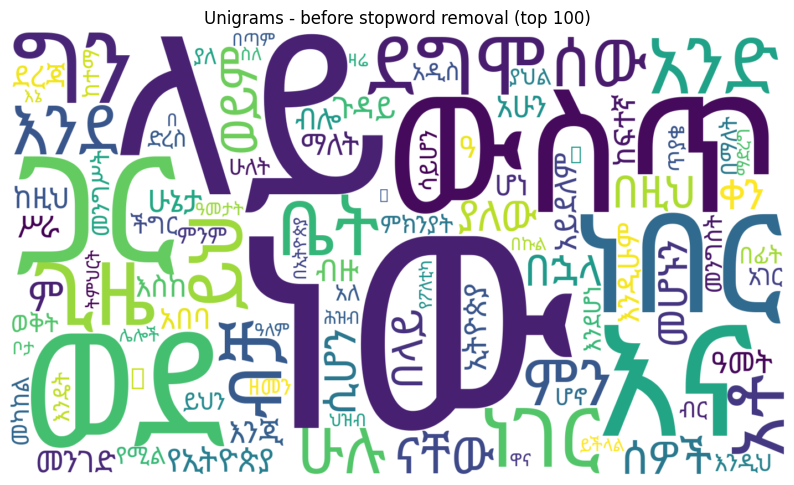

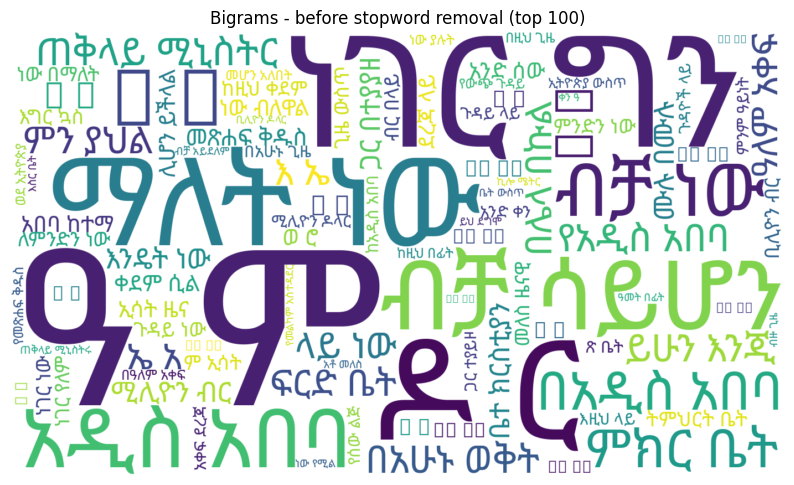

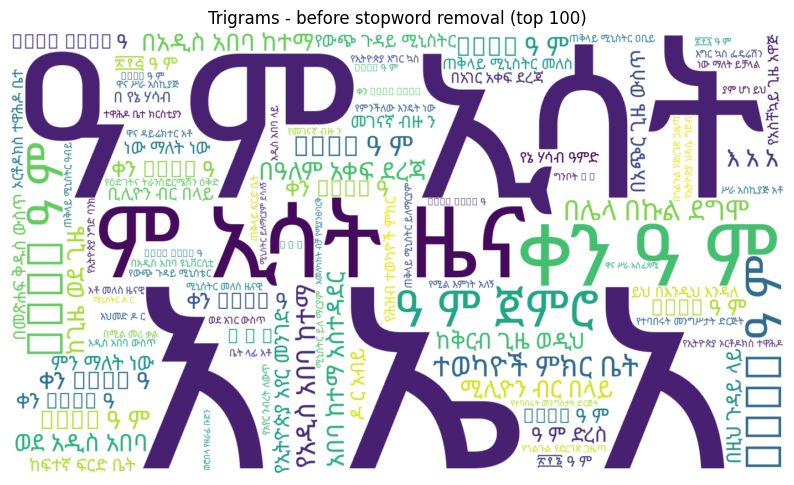

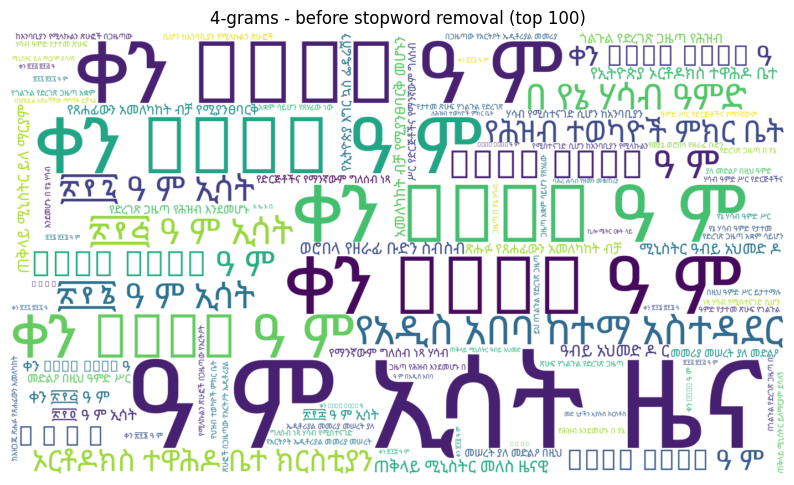

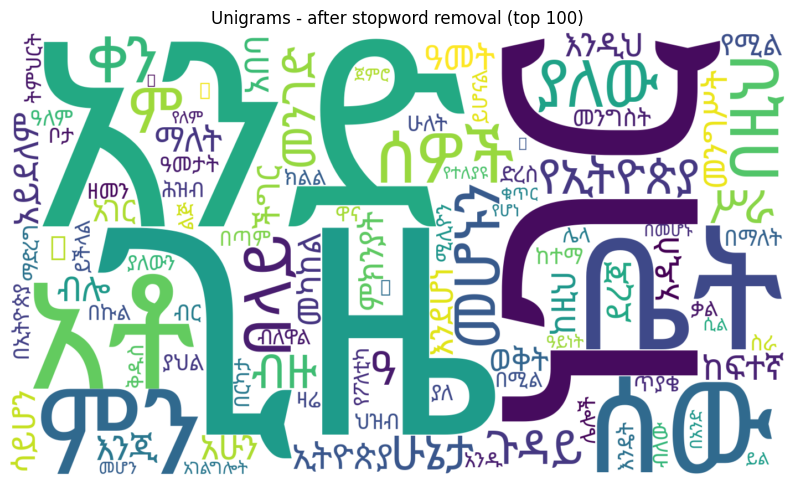

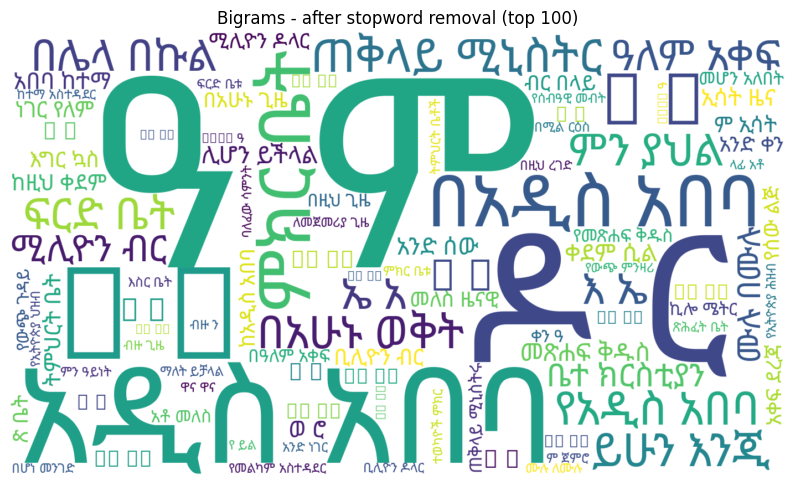

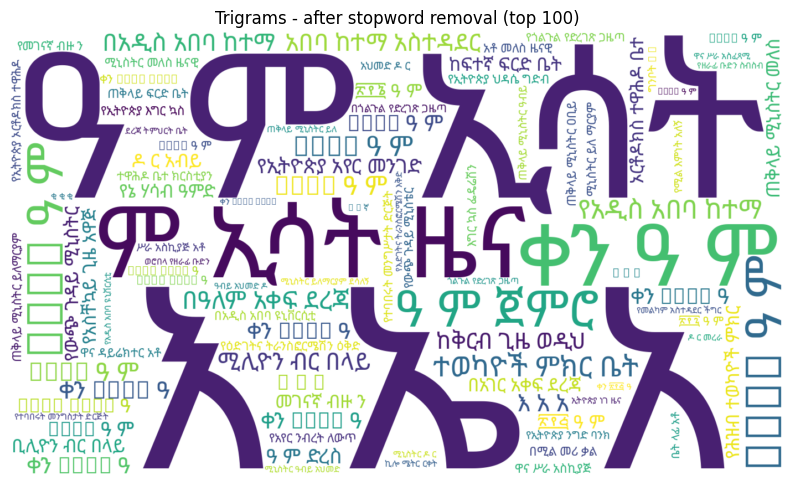

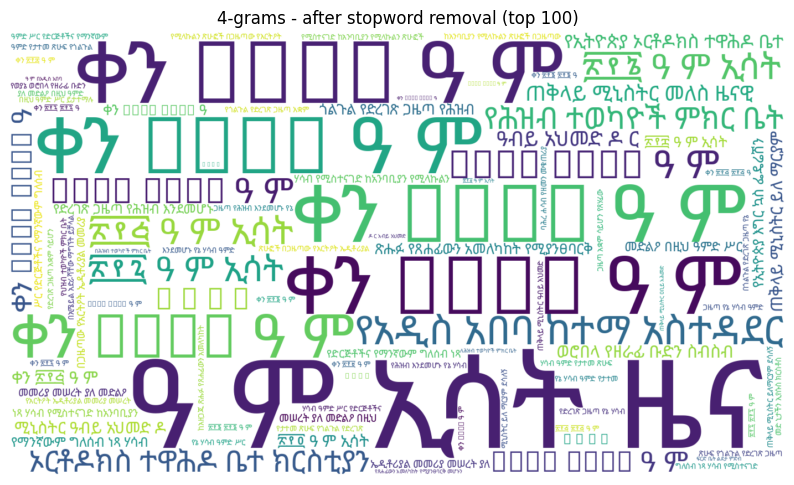

Saved 8 word clouds to /content/gdrive/MyDrive/GPAC_member3_results/wordclouds


In [ ]:
import importlib.util
if importlib.util.find_spec("wordcloud") is None:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "wordcloud"])
# Fonts that contain Amharic (Ethiopic) letters
subprocess.run("apt-get -qq install -y fonts-noto-core fonts-sil-abyssinica fonts-freefont-ttf > /dev/null 2>&1", shell=True)

import matplotlib.pyplot as plt
from wordcloud import WordCloud

FONT_PATH = None
for pattern in ("/usr/share/fonts/**/NotoSansEthiopic-Regular.ttf",
                "/usr/share/fonts/**/AbyssinicaSIL*.ttf",
                "/usr/share/fonts/**/FreeSerif.ttf"):
    found = glob.glob(pattern, recursive=True)
    if found:
        FONT_PATH = found[0]
        break
print("Using font:", FONT_PATH)

ORDER_NAMES = {1: "Unigrams", 2: "Bigrams", 3: "Trigrams", 4: "4-grams"}
saved = []
for v in ("before", "after"):
    for n in range(1, 5):
        freqs = dict(results[n][f"top_{v}"][:100])
        wc = WordCloud(font_path=FONT_PATH, width=1400, height=800, background_color="white",
                       max_words=100, prefer_horizontal=0.95, relative_scaling=0.5,
                       random_state=42).generate_from_frequencies(freqs)
        out_path = WORDCLOUD_DIR / f"wordcloud_{v}_{n}gram.png"
        wc.to_file(str(out_path))
        saved.append(out_path)
        plt.figure(figsize=(10, 6))
        plt.imshow(wc, interpolation="bilinear")
        plt.axis("off")
        plt.title(f"{ORDER_NAMES[n]} - {v} stopword removal (top {len(freqs)})")
        plt.show()

print(f"Saved {len(saved)} word clouds to {WORDCLOUD_DIR}")

This prepares a font and word-cloud dependencies, then visualizes frequent words. Word clouds are exploratory summaries rather than precise statistical charts; use the frequency CSVs for exact comparisons.

Using font: /usr/share/fonts/truetype/freefont/FreeSerif.ttf


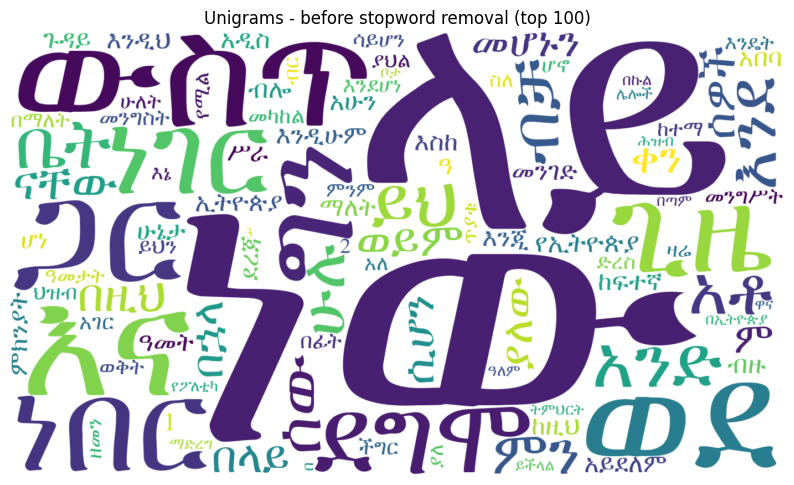

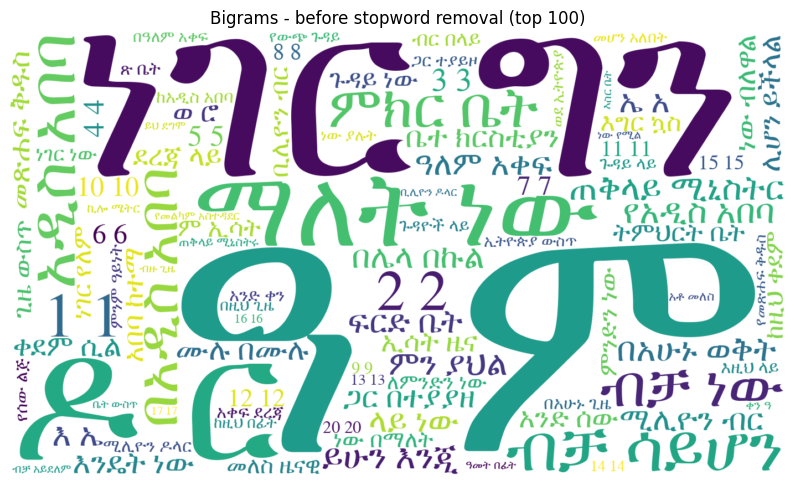

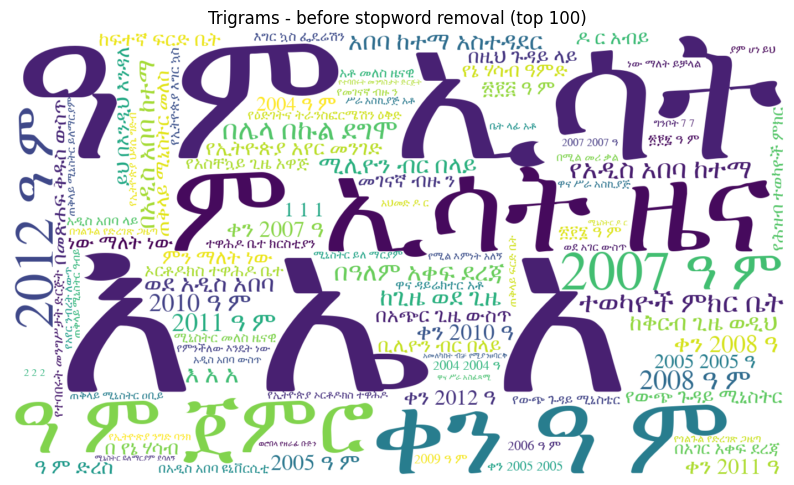

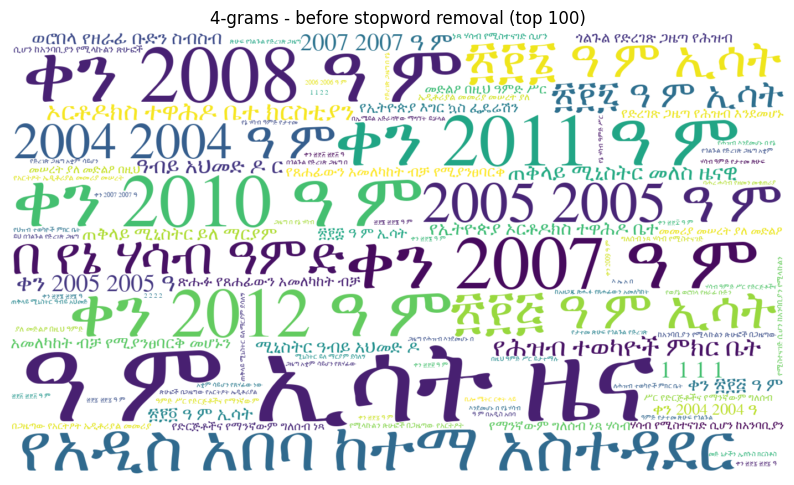

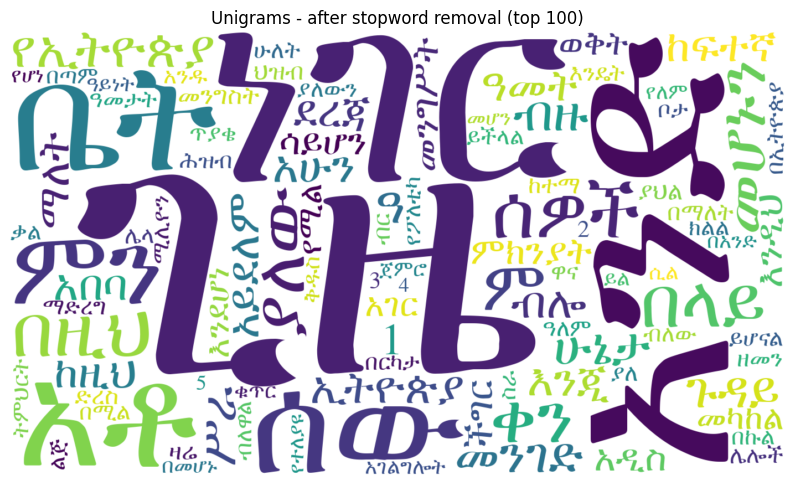

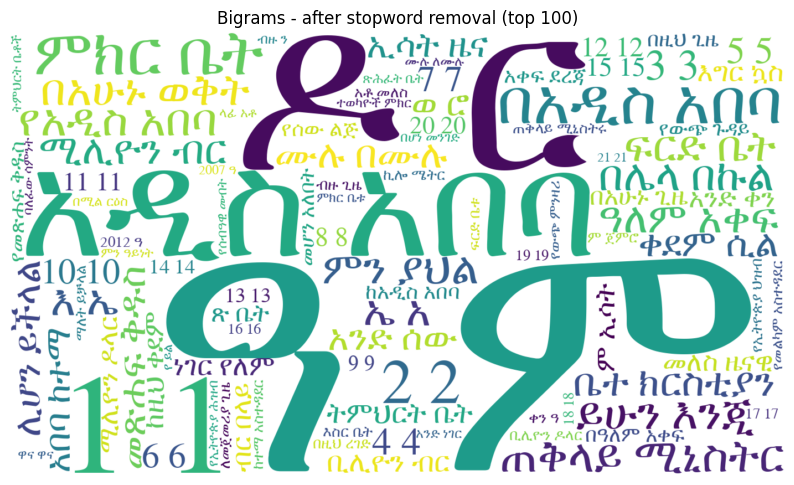

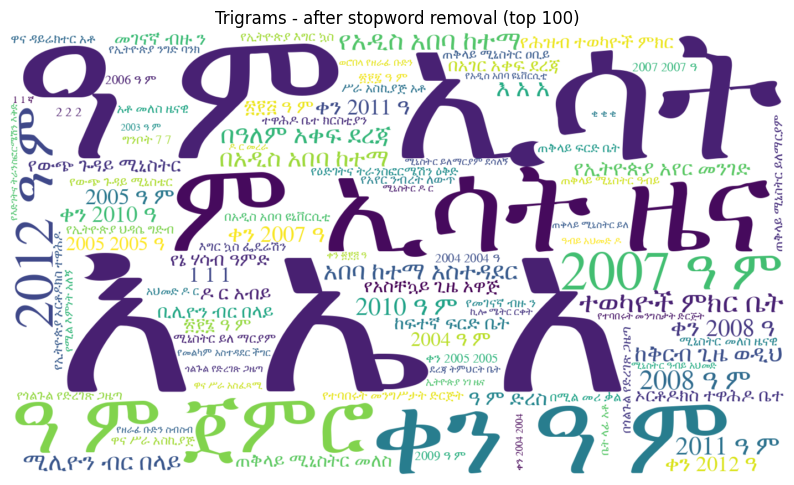

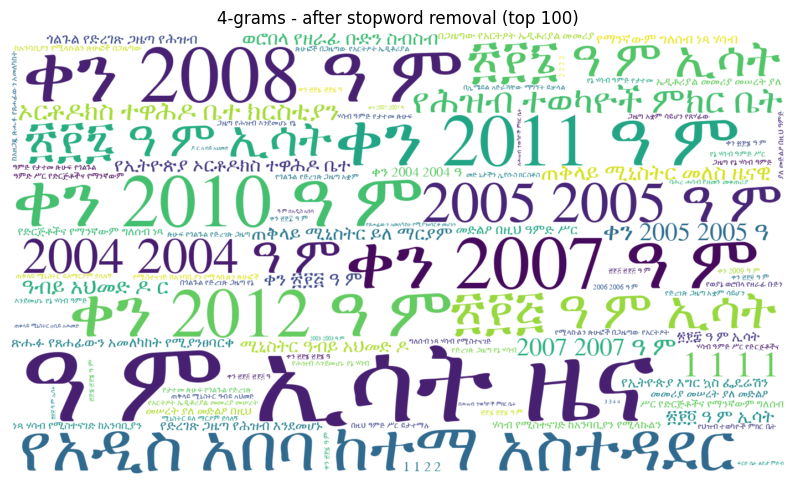

Saved 8 word clouds to /content/gdrive/MyDrive/GPAC_member3_results/wordclouds


In [ ]:
FONT_PATH = None
for pattern in ("/usr/share/fonts/**/FreeSerif.ttf",                 # Amharic AND digits
                "/usr/share/fonts/**/AbyssinicaSIL*.ttf",
                "/usr/share/fonts/**/NotoSansEthiopic-Regular.ttf"):
    found = glob.glob(pattern, recursive=True)
    if found:
        FONT_PATH = found[0]
        break
print("Using font:", FONT_PATH)

saved = []
for v in ("before", "after"):
    for n in range(1, 5):
        freqs = dict(results[n][f"top_{v}"][:100])
        wc = WordCloud(font_path=FONT_PATH, width=1400, height=800, background_color="white",
                       max_words=100, prefer_horizontal=0.95, relative_scaling=0.5,
                       random_state=42).generate_from_frequencies(freqs)
        out_path = WORDCLOUD_DIR / f"wordcloud_{v}_{n}gram.png"
        wc.to_file(str(out_path))
        saved.append(out_path)
        plt.figure(figsize=(10, 6))
        plt.imshow(wc, interpolation="bilinear")
        plt.axis("off")
        plt.title(f"{ORDER_NAMES[n]} - {v} stopword removal (top {len(freqs)})")
        plt.show()

print(f"Saved {len(saved)} word clouds to {WORDCLOUD_DIR}")

This generates and saves word clouds for different n-gram orders and corpus versions. Comparison in before/after images for broad patterns only; font rendering, layout, and word size scaling can affect visual impressions.

In [ ]:
print("Results in your Drive:\n")
for p in sorted(RESULTS_DIR.rglob("*")):
    if p.is_file() and WORK_DIR not in p.parents:
        print(f"  {str(p.relative_to(RESULTS_DIR)):45} {p.stat().st_size/1024**2:8.2f} MB")

TEAM = Path("/content/gdrive/MyDrive/GPAC_NLP_Project/member_3_stopwords")
print("\nTeam folder found:", TEAM.is_dir())
if TEAM.is_dir():
    for p in RESULTS_DIR.rglob("*"):
        if p.is_file() and WORK_DIR not in p.parents and p.name != "GPAC_no_stopwords.txt":
            dest = TEAM / p.relative_to(RESULTS_DIR)
            dest.parent.mkdir(parents=True, exist_ok=True)
            shutil.copy(p, dest)
    print("Copied to member_3_stopwords:")
    for p in sorted(TEAM.rglob("*")):
        if p.is_file():
            print("  ", p.relative_to(TEAM))

Results in your Drive:

  GPAC_no_stopwords.txt                           913.54 MB
  amharic_stopwords.txt                             0.00 MB
  comparison_summary.csv                            0.00 MB
  stopword_frequencies.csv                          0.00 MB
  top10_comparison.csv                              0.00 MB
  top10_ngrams.csv                                  0.00 MB
  wordclouds/wordcloud_after_1gram.png              0.38 MB
  wordclouds/wordcloud_after_2gram.png              0.39 MB
  wordclouds/wordcloud_after_3gram.png              0.43 MB
  wordclouds/wordcloud_after_4gram.png              0.45 MB
  wordclouds/wordcloud_before_1gram.png             0.35 MB
  wordclouds/wordcloud_before_2gram.png             0.40 MB
  wordclouds/wordcloud_before_3gram.png             0.45 MB
  wordclouds/wordcloud_before_4gram.png             0.45 MB

Team folder found: True
Copied to member_3_stopwords:
   Notebook/Stopwords.ipynb
   amharic_stopwords.txt
   comparison_summary.csv
  

This lists generated output files and checks the team-sharing folder. while using the listing to confirm which artifacts were produced and whether the expected files are available for submission or collaboration.

# Part 4 — Probability, train/test split & model evaluation (5 MB sample)

 (Drive mounted once in the shared setup cell). Perplexity and top-k accuracy for unigram → four-gram models.



Reading or loading 5MB of the corpus

In [ ]:
# Correct path pointing directly to the GPAC.txt file inside the Corpus directory
file_path = str(CORPUS_PATH)
sample_size = 5 * 1024 * 1024  # 5 MB

with open(file_path, "rb") as f:
    raw_sample = f.read(sample_size)

# Remove any incomplete UTF-8 character at the end
sample_text = raw_sample.decode("utf-8", errors="ignore")

print("Bytes read:", len(raw_sample))
print("Characters decoded:", len(sample_text))
print("\nSample preview:")
print(sample_text[:1000])


Bytes read: 5242880
Characters decoded: 2053280

Sample preview:
    ምን መሰላችሁ? (አንባቢያን) ኢትዮጵያ በተደጋጋሚ ጥሪው ደርሷት ልትታደመው ያልቻለችው የአለም የእግር ኳስ ዋ ለ19ኛ ጊዜ በደቡብ አፍሪካ ሲጠጣ፣ በሩቅ እያየች አንጀቷ ባረረ ልክ በአመቱ በለስ ቀናትና ሌላ ዋ ልትታደም ሁለት ልጆቿን ወደ ደቡብ አፍሪካ ላከች፡፡6ኛው ቢግ ብራዘርስ አፍሪካ አብሮ የመኖር ውድድር በደቡብ አፍሪካ ተካሂዷል፡፡ ከተለያዩ 14 የአፍሪካ አገራት የተውጣጡ 26 ያህል ተሳታፊዎች የተካፈሉበት ይህ ውድድር፣ ግለሰቦች በፈታኝ ሁኔታ ውስጥ በማለፍ ብቃታቸውን የሚያስመሰክሩበት መሆኑን ሰምተናል፡፡ የሚገጥሟቸውን የተለያዩ ፈተናዎች በትእግስትና በጥበብ ማለፍ፣ ከሌሎች ጋር ተስማምቶ መዝለቅ፣ ችግሮችን በብልጠት መፍታት ወዘተ     በየጊዜው ከሚደረገው ቅነሳ ተርፈው ለ91 ቀናት ያህል በውድድሩ መቆየት የቻሉ ሁለት ተወዳዳሪዎች እያንዳንዳቸው 200 ሺህ ዶላር እንደሚሸለሙም ሲናገር ነበር፡፡ በዘንድሮው ውድድር አገራችን ዳኒ እና ሃኒ የተባሉ ሁለት ወጣቶችን ብታሰልፍም ዳኒ ቀደም ብሎ የቅነሳው ሰለባ ሲሆን ሃኒም በቅርቡ ከውድድር ውጭ ሆናለች፡፡ይህቺን የአገሪቱ ብቸኛ ተስፋ ወደ አሸናፊነት ለማሸጋገር የህዝብ የድጋፍ ድም ወሳኝ መሆኑን የተገነዘበው ወዳጄ ነው እንግዲህ                835  የሚል አገራዊ ጥሪ ያስተላለፈልኝ   ያኔ ሃኒ ከውድድሩ ከመሰናበቷ በፊት፡፡ወዳጄ የአገሩን ስም በአሸናፊነት የማስጠራት ከፍተኛ ጉጉት፣ አገሬ እንዳትሸነፍ የሚል ከፍተኛ ስጋት እንዳደረበት ይሰማኛል፡፡ ጉጉቱ ሳይሆን ስጋቱ የወዳጄን የዋህነት         ፡፡ሃኒም ኢትዮጵያም ይሸነፉ ይሆን? በሚል እንዲህ ከንቱ ስጋት የሚያንገበግባቸውን አገር ወዳድ ዜጐች 

This reads a 5 MB sample from the corpus and previews the decoded text. Because the sample is taken from the start of the file and UTF-8 decoding ignores a possibly incomplete final character, it is a convenient sample rather than a random or corpus-wide sample.

**Check how sentence segmentation works**

*   identify sentence boundaries before tokenzation



In [ ]:
# Candidate sentence-ending markers
sentence_pattern = r"፡፡|[።፧?!]"

sentences = [
    s.strip()
    for s in re.split(sentence_pattern, sample_text)
    if s.strip()
]

print("Number of candidate sentences:", len(sentences))
print("\nFirst 5 sentences:\n")

for i, sentence in enumerate(sentences[:5], start=1):
    print(f"{i}. {sentence}\n")


Number of candidate sentences: 29298

First 5 sentences:

1. ምን መሰላችሁ

2. (አንባቢያን) ኢትዮጵያ በተደጋጋሚ ጥሪው ደርሷት ልትታደመው ያልቻለችው የአለም የእግር ኳስ ዋ ለ19ኛ ጊዜ በደቡብ አፍሪካ ሲጠጣ፣ በሩቅ እያየች አንጀቷ ባረረ ልክ በአመቱ በለስ ቀናትና ሌላ ዋ ልትታደም ሁለት ልጆቿን ወደ ደቡብ አፍሪካ ላከች

3. 6ኛው ቢግ ብራዘርስ አፍሪካ አብሮ የመኖር ውድድር በደቡብ አፍሪካ ተካሂዷል

4. ከተለያዩ 14 የአፍሪካ አገራት የተውጣጡ 26 ያህል ተሳታፊዎች የተካፈሉበት ይህ ውድድር፣ ግለሰቦች በፈታኝ ሁኔታ ውስጥ በማለፍ ብቃታቸውን የሚያስመሰክሩበት መሆኑን ሰምተናል

5. የሚገጥሟቸውን የተለያዩ ፈተናዎች በትእግስትና በጥበብ ማለፍ፣ ከሌሎች ጋር ተስማምቶ መዝለቅ፣ ችግሮችን በብልጠት መፍታት ወዘተ     በየጊዜው ከሚደረገው ቅነሳ ተርፈው ለ91 ቀናት ያህል በውድድሩ መቆየት የቻሉ ሁለት ተወዳዳሪዎች እያንዳንዳቸው 200 ሺህ ዶላር እንደሚሸለሙም ሲናገር ነበር



This segments the sample using the selected sentence-ending markers and displays examples. The count is a sample-level result, not a full-corpus sentence total; inspect examples for abbreviations or punctuation cases that may split incorrectly.

**Tokenize the sentences**

In [ ]:
# Punctuation normalization based on the team's preliminary policy
punctuation_pattern = r"[፡።፣፤፥፦፧፨?!,.;:()\[\]\"'፠፡]"

def tokenize(sentence):
    cleaned = re.sub(punctuation_pattern, " ", sentence)
    return cleaned.split()

tokenized_sentences = [tokenize(s) for s in sentences]

print("First 5 tokenized sentences:\n")

for tokens in tokenized_sentences[:5]:
    print(tokens)

total_tokens = sum(len(tokens) for tokens in tokenized_sentences)
unique_tokens = len({
    token
    for tokens in tokenized_sentences
    for token in tokens
})

print("\nTotal tokens:", total_tokens)
print("Unique tokens:", unique_tokens)


First 5 tokenized sentences:

['ምን', 'መሰላችሁ']
['አንባቢያን', 'ኢትዮጵያ', 'በተደጋጋሚ', 'ጥሪው', 'ደርሷት', 'ልትታደመው', 'ያልቻለችው', 'የአለም', 'የእግር', 'ኳስ', 'ዋ', 'ለ19ኛ', 'ጊዜ', 'በደቡብ', 'አፍሪካ', 'ሲጠጣ', 'በሩቅ', 'እያየች', 'አንጀቷ', 'ባረረ', 'ልክ', 'በአመቱ', 'በለስ', 'ቀናትና', 'ሌላ', 'ዋ', 'ልትታደም', 'ሁለት', 'ልጆቿን', 'ወደ', 'ደቡብ', 'አፍሪካ', 'ላከች']
['6ኛው', 'ቢግ', 'ብራዘርስ', 'አፍሪካ', 'አብሮ', 'የመኖር', 'ውድድር', 'በደቡብ', 'አፍሪካ', 'ተካሂዷል']
['ከተለያዩ', '14', 'የአፍሪካ', 'አገራት', 'የተውጣጡ', '26', 'ያህል', 'ተሳታፊዎች', 'የተካፈሉበት', 'ይህ', 'ውድድር', 'ግለሰቦች', 'በፈታኝ', 'ሁኔታ', 'ውስጥ', 'በማለፍ', 'ብቃታቸውን', 'የሚያስመሰክሩበት', 'መሆኑን', 'ሰምተናል']
['የሚገጥሟቸውን', 'የተለያዩ', 'ፈተናዎች', 'በትእግስትና', 'በጥበብ', 'ማለፍ', 'ከሌሎች', 'ጋር', 'ተስማምቶ', 'መዝለቅ', 'ችግሮችን', 'በብልጠት', 'መፍታት', 'ወዘተ', 'በየጊዜው', 'ከሚደረገው', 'ቅነሳ', 'ተርፈው', 'ለ91', 'ቀናት', 'ያህል', 'በውድድሩ', 'መቆየት', 'የቻሉ', 'ሁለት', 'ተወዳዳሪዎች', 'እያንዳንዳቸው', '200', 'ሺህ', 'ዶላር', 'እንደሚሸለሙም', 'ሲናገር', 'ነበር']

Total tokens: 384398
Unique tokens: 87746


This normalizes punctuation and tokenizes the segmented sentences. The preview helps verify that punctuation is removed without accidentally merging words; tokenization choices directly affect all subsequent n-gram statistics.

**calculate N-grams**

In [ ]:
unigrams = Counter()
bigrams = Counter()
trigrams = Counter()
fourgrams = Counter()

for tokens in tokenized_sentences:
    unigrams.update(tokens)

    bigrams.update(zip(tokens, tokens[1:]))
    trigrams.update(zip(tokens, tokens[1:], tokens[2:]))
    fourgrams.update(zip(tokens, tokens[1:], tokens[2:], tokens[3:]))

print("Unique unigrams:", len(unigrams))
print("Unique bigrams:", len(bigrams))
print("Unique trigrams:", len(trigrams))
print("Unique four-grams:", len(fourgrams))

print("\nTop 10 unigrams:")
for word, count in unigrams.most_common(10):
    print(word, count)

print("\nTop 10 bigrams:")
for gram, count in bigrams.most_common(10):
    print(gram, count)

Unique unigrams: 87746
Unique bigrams: 278254
Unique trigrams: 292333
Unique four-grams: 271623

Top 10 unigrams:
ነው 6511
ላይ 3302
ነበር 1925
ወደ 1903
ግን 1838
እና 1769
ውስጥ 1661
ጋር 1482
ነገር 1284
አንድ 1236

Top 10 bigrams:
('ዓ', 'ም') 543
('ነገር', 'ግን') 291
('ማለት', 'ነው') 220
('ብቻ', 'ሳይሆን') 210
('ብቻ', 'ነው') 204
('አዲስ', 'አበባ') 134
('ምን', 'ያህል') 117
('እ', 'ኤ') 114
('ኤ', 'አ') 114
('አንድ', 'ቀን') 96


This counts unique unigrams, bigrams, trigrams, and four-grams in the 5 MB sample and reports frequent examples. These are sample statistics and should not be presented as full-corpus counts.

**calculate N-gram probabilities**

In [ ]:
bigram_probabilities = {}

for (word1, word2), count in bigrams.items():
    bigram_probabilities[(word1, word2)] = (
        count / unigrams[word1]
    )

print("Top 10 bigrams by conditional probability:")

top_bigrams = sorted(
    bigram_probabilities.items(),
    key=lambda item: item[1],
    reverse=True
)[:10]

for (word1, word2), probability in top_bigrams:
    print(
        f"{word1} {word2}: {probability:.4f}"
    )

Top 10 bigrams by conditional probability:
ደርሷት ልትታደመው: 1.0000
ልትታደመው ያልቻለችው: 1.0000
ለ19ኛ ጊዜ: 1.0000
አንጀቷ ባረረ: 1.0000
ባረረ ልክ: 1.0000
ልትታደም ሁለት: 1.0000
6ኛው ቢግ: 1.0000
በፈታኝ ሁኔታ: 1.0000
የሚያስመሰክሩበት መሆኑን: 1.0000
የሚገጥሟቸውን የተለያዩ: 1.0000


This estimates conditional bigram probabilities as count(word1, word2) / count(word1). Probabilities of 1.0 can occur for rare first words that have only one observed continuation, so the next cell adds a minimum-frequency filter for more reliable interpretation.



> checking the probality



In [ ]:
print("Top bigrams by conditional probability, with counts:\n")

for (word1, word2), probability in top_bigrams:
    print(
        f"{word1} {word2} | "
        f"Bigram count: {bigrams[(word1, word2)]} | "
        f"First-word count: {unigrams[word1]} | "
        f"Probability: {probability:.4f}"
    )

Top bigrams by conditional probability, with counts:

ደርሷት ልትታደመው | Bigram count: 1 | First-word count: 1 | Probability: 1.0000
ልትታደመው ያልቻለችው | Bigram count: 1 | First-word count: 1 | Probability: 1.0000
ለ19ኛ ጊዜ | Bigram count: 1 | First-word count: 1 | Probability: 1.0000
አንጀቷ ባረረ | Bigram count: 1 | First-word count: 1 | Probability: 1.0000
ባረረ ልክ | Bigram count: 1 | First-word count: 1 | Probability: 1.0000
ልትታደም ሁለት | Bigram count: 1 | First-word count: 1 | Probability: 1.0000
6ኛው ቢግ | Bigram count: 1 | First-word count: 1 | Probability: 1.0000
በፈታኝ ሁኔታ | Bigram count: 1 | First-word count: 1 | Probability: 1.0000
የሚያስመሰክሩበት መሆኑን | Bigram count: 1 | First-word count: 1 | Probability: 1.0000
የሚገጥሟቸውን የተለያዩ | Bigram count: 1 | First-word count: 1 | Probability: 1.0000


This prints the top conditional bigrams together with their supporting counts. Always read probability alongside count: a high probability based on one occurrence is weak evidence of a stable language pattern.

In [ ]:
reliable_bigrams = [
    (gram, probability)
    for gram, probability in bigram_probabilities.items()
    if unigrams[gram[0]] >= 20
]

reliable_bigrams.sort(
    key=lambda item: item[1],
    reverse=True
)

print("Top 10 bigrams with first-word count >= 20:\n")

for (word1, word2), probability in reliable_bigrams[:10]:
    print(
        f"{word1} {word2}: {probability:.4f} "
        f"(bigram count: {bigrams[(word1, word2)]}, "
        f"first-word count: {unigrams[word1]})"
    )


Top 10 bigrams with first-word count >= 20:

በነገራችን ላይ: 1.0000 (bigram count: 39, first-word count: 39)
ለመጀመሪያ ጊዜ: 1.0000 (bigram count: 35, first-word count: 35)
ሲልቪዮ ቤርሉስኮኒ: 1.0000 (bigram count: 21, first-word count: 21)
ብላታ ወልደጊዮርጊስ: 0.9643 (bigram count: 27, first-word count: 28)
ይለ ሥላሴ: 0.9231 (bigram count: 24, first-word count: 26)
2004 ዓ: 0.9231 (bigram count: 48, first-word count: 52)
ዓ ም: 0.9188 (bigram count: 543, first-word count: 591)
ኢብን ባቱታ: 0.9143 (bigram count: 32, first-word count: 35)
የፕሬዚዳንቱን ንግግር: 0.9130 (bigram count: 21, first-word count: 23)
ቻርለስ ዲከንስ: 0.9062 (bigram count: 29, first-word count: 32)


This filters to bigrams whose first word appears at least 20 times, reducing some rare-context effects. The threshold is a heuristic rather than a universal rule; it makes the displayed probabilities more interpretable but does not eliminate all sampling bias.

**prepare training and test data**

Before calculating perplexity or next-word accuracy, we need to separate the sentences into:
- Training set: used to learn N-gram counts and probabilities.
- Test set: held aside to evaluate how well the model predicts text it hasn't learned from.


> shuffle- helps distribute the different sentences across both sets. The fixed seed 42 makes the split reproducible.






In [ ]:
# Keep only non-empty sentences
sentences_for_eval = [
    tokens for tokens in tokenized_sentences if tokens
]

# Shuffle reproducibly
random.seed(42)
random.shuffle(sentences_for_eval)

# Split into 80% training and 20% testing
split_index = int(0.8 * len(sentences_for_eval))

train_sentences = sentences_for_eval[:split_index]
test_sentences = sentences_for_eval[split_index:]

print("Total sentences:", len(sentences_for_eval))
print("Training sentences:", len(train_sentences))
print("Testing sentences:", len(test_sentences))

Total sentences: 29295
Training sentences: 23436
Testing sentences: 5859


This removes empty sentences, shuffles reproducibly, and creates an 80/20 train/test split. The fixed seed makes the split repeatable; keeping test data separate from training is necessary for a fair evaluation.

**Prepare the Vocabulary and Count Training Bigrams**

In [ ]:
# Count words in the training set only
word_frequency = Counter(
    word
    for sentence in train_sentences
    for word in sentence
)

# Keep words that occur at least twice
vocabulary = {
    word for word, count in word_frequency.items()
    if count >= 2
}
vocabulary.add("<UNK>")
def map_unknown_words(sentences):
    return [
        [
            word if word in vocabulary else "<UNK>"
            for word in sentence
        ]
        for sentence in sentences
    ]

train_mapped = map_unknown_words(train_sentences)
test_mapped = map_unknown_words(test_sentences)

bigram_counts = Counter()
context_counts = Counter()

for sentence in train_mapped:
    sequence = ["<s>"] + sentence

    for i in range(len(sequence) - 1):
        context = sequence[i]
        next_word = sequence[i + 1]

        bigram_counts[(context, next_word)] += 1
        context_counts[context] += 1

vocab_size = len(vocabulary)

print("Vocabulary size:", vocab_size)
print("Training bigrams:", sum(bigram_counts.values()))
print("Test sentences:", len(test_mapped))
print("Example mapped sentence:", test_mapped[0])
# Prepare bigram predictions for next-word evaluation


next_word_counts = defaultdict(Counter)

for (context, word), count in bigram_counts.items():
    next_word_counts[context][word] += count

Vocabulary size: 28540
Training bigrams: 306974
Test sentences: 5859
Example mapped sentence: ['<UNK>', 'ፊልም', 'ሥራ', 'እንዴት', 'ነው']


This builds the vocabulary using training data only and maps rare/unseen words to <UNK>. Training-only vocabulary construction avoids leakage from the test set; the minimum-frequency threshold trades vocabulary coverage against sparsity.

**Calculate perplexity**


> Perplexity is a measure of how uncertain the model is when predicting the next word.



*   Lower perplexity generally means the model predicts the test text better.
*   Higher perplexity generally means it finds the test text harder to predict.





In [ ]:
def calculate_perplexity(sentences):
    total_log_probability = 0
    total_words = 0

    for sentence in sentences:
        sequence = ["<s>"] + sentence

        for i in range(1, len(sequence)):
            context = sequence[i - 1]
            word = sequence[i]

            count_bigram = bigram_counts[(context, word)]
            count_context = context_counts[context]

            probability = (
                (count_bigram + 1)
                / (count_context + vocab_size)
            )

            total_log_probability += math.log(probability)
            total_words += 1

    return math.exp(-total_log_probability / total_words)

perplexity = calculate_perplexity(test_mapped)

print("Bigram model perplexity:", round(perplexity, 2))

Bigram model perplexity: 5998.44


This calculates bigram perplexity with add-one smoothing. Lower perplexity generally indicates better predictive fit under the same evaluation setup, but the score is sensitive to tokenization, vocabulary size, unknown-word handling, and smoothing choices.

**Evaluation on bigram**

In [ ]:
# 9. Evaluation on bigram


# Most frequent known words for fallback predictions
unigram_counts = Counter(
    word for sentence in train_mapped for word in sentence
)

known_top5 = [
    word for word, count in unigram_counts.most_common()
    if word != "<UNK>"
][:5]


def evaluate_known_words(test_sentences, k=5):
    correct_top1 = 0
    correct_top5 = 0
    total_known = 0
    total_tokens = 0

    for original_sentence in test_sentences:
        # Map rare/unseen words to <UNK>
        mapped_sentence = [
            word if word in vocabulary else "<UNK>"
            for word in original_sentence
        ]

        # Add the start marker only to the mapped sentence
        sequence = ["<s>"] + mapped_sentence

        # Use the original sentence's index for the actual word
        for i in range(len(original_sentence)):
            actual_original = original_sentence[i]
            context = sequence[i]

            total_tokens += 1

            # Evaluate only words included in the vocabulary
            if actual_original not in vocabulary:
                continue

            total_known += 1

            # Predict using the most frequent bigram continuations
            candidates = [
                word
                for word, count in
                next_word_counts.get(context, Counter()).most_common()
                if word != "<UNK>"
            ][:k]

            # Fall back to frequent unigram predictions if needed
            if not candidates:
                candidates = known_top5[:k]

            if candidates and candidates[0] == actual_original:
                correct_top1 += 1

            if actual_original in candidates:
                correct_top5 += 1

    return {
        "Known-word coverage": total_known / total_tokens
            if total_tokens else 0,
        "Top-1 accuracy": correct_top1 / total_known
            if total_known else 0,
        "Top-5 accuracy": correct_top5 / total_known
            if total_known else 0,
        "Known test tokens": total_known,
        "All test tokens": total_tokens
    }


known_results = evaluate_known_words(test_sentences)

for metric, value in known_results.items():
    if isinstance(value, float):
        print(f"{metric}: {value:.4f} ({value * 100:.2f}%)")
    else:
        print(f"{metric}: {value:,}")


Known-word coverage: 0.7745 (77.45%)
Top-1 accuracy: 0.1118 (11.18%)
Top-5 accuracy: 0.2084 (20.84%)
Known test tokens: 59,966
All test tokens: 77,424


This evaluates bigram next-word predictions on known test tokens and reports coverage plus top-1/top-5 accuracy. Coverage says what fraction of test tokens are in-vocabulary; accuracy should be interpreted alongside that coverage and compared only on the same evaluation subset.

**Evaltaion on unigram**

In [ ]:
# Unigram baseline: most frequent known words
known_top5 = [
    word
    for word, count in unigram_counts.most_common()
    if word != "<UNK>"
][:5]


def evaluate_unigram_known(test_sentences, k=5):
    correct_top1 = 0
    correct_top5 = 0
    total_known = 0

    for sentence in test_sentences:
        for actual_word in sentence:
            # Exclude words that were mapped to <UNK>
            if actual_word not in vocabulary:
                continue

            total_known += 1

            if known_top5[0] == actual_word:
                correct_top1 += 1

            if actual_word in known_top5[:k]:
                correct_top5 += 1

    return {
        "Top-1 accuracy": correct_top1 / total_known,
        "Top-5 accuracy": correct_top5 / total_known,
        "Known test tokens": total_known
    }


unigram_known_results = evaluate_unigram_known(test_sentences)

print("Unigram baseline — known words only")

for metric, value in unigram_known_results.items():
    if isinstance(value, float):
        print(f"{metric}: {value:.2%}")
    else:
        print(f"{metric}: {value}")

Unigram baseline — known words only
Top-1 accuracy: 2.23%
Top-5 accuracy: 5.33%
Known test tokens: 59966


This establishes a unigram baseline using the most frequent training words. It ignores context, so it provides a useful lower-complexity reference for judging whether bigram or trigram context improves next-word prediction.

--------------------------------------

In [ ]:
train_total = sum(len(s) for s in train_sentences)
test_total = sum(len(s) for s in test_sentences)

train_unknown = sum(
    word == "<UNK>"
    for sentence in train_mapped
    for word in sentence
)

test_unknown = sum(
    word == "<UNK>"
    for sentence in test_mapped
    for word in sentence
)

print("Training tokens:", train_total)
print("Training tokens mapped to UNK:", train_unknown)
print("Training UNK percentage:",
      f"{train_unknown / train_total * 100:.2f}%")

print("\nTest tokens:", test_total)
print("Test tokens mapped to UNK:", test_unknown)
print("Test UNK percentage:",
      f"{test_unknown / test_total * 100:.2f}%")

Training tokens: 306974
Training tokens mapped to UNK: 47929
Training UNK percentage: 15.61%

Test tokens: 77424
Test tokens mapped to UNK: 17458
Test UNK percentage: 22.55%


This reports training/test token totals and the proportion mapped to <UNK>. A larger unknown rate in the test set than the training set is expected with held-out data and highlights the limits imposed by the vocabulary cutoff.

**Evaluation** **on trigram**

In [ ]:
# Count trigrams from training data
trigram_counts = Counter()
trigram_context_counts = Counter()

for sentence in train_mapped:
    sequence = ["<s>", "<s>"] + sentence

    for i in range(2, len(sequence)):
        context = (sequence[i - 2], sequence[i - 1])
        word = sequence[i]

        trigram_counts[(context, word)] += 1
        trigram_context_counts[context] += 1

# Precompute ranked predictions for each context
trigram_top_words = defaultdict(list)

for (context, word), count in trigram_counts.items():
    if word != "<UNK>":
        trigram_top_words[context].append((word, count))

for context in trigram_top_words:
    trigram_top_words[context].sort(
        key=lambda item: item[1], reverse=True
    )
    trigram_top_words[context] = [
        word for word, count in trigram_top_words[context][:5]
    ]

# Evaluate on known test words
correct_top1 = 0
correct_top5 = 0
total_known = 0
total_tokens = 0

for original_sentence in test_sentences:
    mapped = [
        word if word in vocabulary else "<UNK>"
        for word in original_sentence
    ]
    sequence = ["<s>", "<s>"] + mapped

    for i, actual_word in enumerate(original_sentence):
        total_tokens += 1

        if actual_word not in vocabulary:
            continue

        total_known += 1
        context = (sequence[i], sequence[i + 1])

        candidates = trigram_top_words.get(context, [])

        # Fall back to bigram predictions
        if not candidates:
            previous_word = sequence[i + 1]
            candidates = [
                word for word, count in
                next_word_counts.get(previous_word, Counter()).most_common()
                if word != "<UNK>"
            ][:5]

        # Fall back to unigram predictions
        if not candidates:
            candidates = known_top5

        if candidates and candidates[0] == actual_word:
            correct_top1 += 1

        if actual_word in candidates:
            correct_top5 += 1

trigram_results = {
    "Known-word coverage": total_known / total_tokens,
    "Top-1 accuracy": correct_top1 / total_known,
    "Top-5 accuracy": correct_top5 / total_known,
    "Known test tokens": total_known,
    "All test tokens": total_tokens
}

for metric, value in trigram_results.items():
    if isinstance(value, float):
        print(f"{metric}: {value:.4f} ({value * 100:.2f}%)")
    else:
        print(f"{metric}: {value:,}")


Known-word coverage: 0.7745 (77.45%)
Top-1 accuracy: 0.1726 (17.26%)
Top-5 accuracy: 0.2370 (23.70%)
Known test tokens: 59,966
All test tokens: 77,424


This counts trigrams from training data and evaluates context-based next-word predictions. Trigrams can use richer context than bigrams, but many contexts are sparse; compare the measured accuracy and coverage rather than assuming a larger n is always better.

** Comparison of N-gram Models**

In [ ]:
# 12. Comparison of N-gram Models

models = {
    "Unigram": {
        "Top-1 accuracy": 0.0223,
        "Top-5 accuracy": 0.0533
    },
    "Bigram": known_results,
    "Trigram": trigram_results
}

print(f"{'Model':<12} {'Top-1 Accuracy':>16} {'Top-5 Accuracy':>16}")
print("-" * 46)

for name, results in models.items():
    print(
        f"{name:<12} "
        f"{results['Top-1 accuracy'] * 100:>15.2f}% "
        f"{results['Top-5 accuracy'] * 100:>15.2f}%"
    )


Model          Top-1 Accuracy   Top-5 Accuracy
----------------------------------------------
Unigram                 2.23%            5.33%
Bigram                 11.18%           20.84%
Trigram                17.26%           23.70%


This compares unigram, bigram, and trigram top-1/top-5 accuracy. The table shows whether context improves prediction in this split; conclusions are strongest when all models use the same test tokens, vocabulary policy, and fallback rules.

**Perplexity** **Comparison**

In [ ]:
# 13. Intrinsic Evaluation — Perplexity Comparison


# Vocabulary size used for add-one smoothing
V = len(vocabulary)

# -------------------------
# 1. Unigram perplexity
# -------------------------

unigram_counts = Counter(
    word for sentence in train_mapped for word in sentence
)

total_training_tokens = sum(unigram_counts.values())


def unigram_perplexity(test_data):
    total_log_probability = 0
    total_words = 0

    for sentence in test_data:
        for word in sentence:
            count = unigram_counts[word]
            probability = (count + 1) / (total_training_tokens + V)

            total_log_probability += math.log(probability)
            total_words += 1

    return math.exp(-total_log_probability / total_words)


# -------------------------
# 2. Bigram perplexity
# -------------------------

def bigram_perplexity(test_data):
    total_log_probability = 0
    total_words = 0

    for sentence in test_data:
        sequence = ["<s>"] + sentence

        for i in range(1, len(sequence)):
            context = sequence[i - 1]
            word = sequence[i]

            count = bigram_counts[(context, word)]
            context_count = context_counts[context]

            probability = (count + 1) / (context_count + V)

            total_log_probability += math.log(probability)
            total_words += 1

    return math.exp(-total_log_probability / total_words)


# -------------------------
# 3. Trigram perplexity
# -------------------------

def trigram_perplexity(test_data):
    total_log_probability = 0
    total_words = 0

    for sentence in test_data:
        sequence = ["<s>", "<s>"] + sentence

        for i in range(2, len(sequence)):
            context = (sequence[i - 2], sequence[i - 1])
            word = sequence[i]

            count = trigram_counts[(context, word)]
            context_count = trigram_context_counts[context]

            probability = (count + 1) / (context_count + V)

            total_log_probability += math.log(probability)
            total_words += 1

    return math.exp(-total_log_probability / total_words)


# -------------------------
# 4. Calculate and compare
# -------------------------

uni_ppl = unigram_perplexity(test_mapped)
bi_ppl = bigram_perplexity(test_mapped)
tri_ppl = trigram_perplexity(test_mapped)

print("Perplexity Comparison")
print("-" * 35)
print(f"Unigram perplexity: {uni_ppl:.2f}")
print(f"Bigram perplexity:  {bi_ppl:.2f}")
print(f"Trigram perplexity: {tri_ppl:.2f}")


Perplexity Comparison
-----------------------------------
Unigram perplexity: 1535.74
Bigram perplexity:  5998.44
Trigram perplexity: 14503.39


This compares unigram, bigram, and trigram perplexity using the defined evaluation and smoothing procedures. Perplexity values are only directly comparable when tokenization, vocabulary, unknown-word policy, and test set are consistent across models.

**Four-gram Perplexity**

In [ ]:
# 14. Four-gram Perplexity


# Count four-grams using the training data only
fourgram_counts = Counter()
fourgram_context_counts = Counter()

for sentence in train_mapped:
    sequence = ["<s>", "<s>", "<s>"] + sentence

    for i in range(3, len(sequence)):
        context = tuple(sequence[i-3:i])
        word = sequence[i]

        fourgram_counts[(context, word)] += 1
        fourgram_context_counts[context] += 1

print("Unique four-grams:", len(fourgram_counts))


def fourgram_perplexity(test_data):
    total_log_probability = 0
    total_words = 0

    for sentence in test_data:
        sequence = ["<s>", "<s>", "<s>"] + sentence

        for i in range(3, len(sequence)):
            context = tuple(sequence[i-3:i])
            word = sequence[i]

            count = fourgram_counts[(context, word)]
            context_count = fourgram_context_counts[context]

            # Add-one (Laplace) smoothing
            probability = (count + 1) / (context_count + V)

            total_log_probability += math.log(probability)
            total_words += 1

    if total_words == 0:
        return float("inf")

    return math.exp(-total_log_probability / total_words)


four_ppl = fourgram_perplexity(test_mapped)

print(f"Four-gram perplexity: {four_ppl:.2f}")


Unique four-grams: 259872
Four-gram perplexity: 18069.93


This estimates four-gram perplexity from training counts. Longer context can capture more local structure but creates many unseen contexts; if four-gram perplexity is higher, sparsity and smoothing may outweigh the benefit of extra context.

**Final Perplexity Comparison**

In [ ]:
# 15. Final Perplexity Comparison

perplexity_results = {
    "Unigram": uni_ppl,
    "Bigram": bi_ppl,
    "Trigram": tri_ppl,
    "Four-gram": four_ppl
}

print("Final Perplexity Comparison")
print("-" * 35)

for model, perplexity in perplexity_results.items():
    print(f"{model}: {perplexity:.2f}")


Final Perplexity Comparison
-----------------------------------
Unigram: 1535.74
Bigram: 5998.44
Trigram: 14503.39
Four-gram: 18069.93


This summarizes perplexity across the evaluated n-gram models. Under a consistent setup, lower perplexity indicates better predictive fit; the current ranking should be interpreted in light of the smoothing and unknown-token handling used by each model.